# Deep Attention Neural Network for Facial Emotion Recognition
## FER2013 — Training, Evaluation and Inference Pipeline

**Project:** Emotion-aware receptionist robot (FYP) — facial-expression analysis from a live camera feed.

| Item | Detail |
|---|---|
| Task | 7-class facial emotion classification from a single face image |
| Dataset | FER2013 (official train/test image folders, 48x48 grayscale — exact counts reported at load time) |
| Model | Deep convolutional network with **channel + spatial (CBAM-style) attention** |
| Framework | PyTorch (data pipeline kept framework-agnostic for portability) |
| Runtime | CPU or CUDA — selected automatically |

---

## 1. Objective

### 1.1 What is facial emotion recognition?

Facial emotion recognition (FER) is the computer-vision task of inferring a person's emotional
state from the appearance of their face in an image or video frame. Because facial expressions
are among the most immediate non-verbal signals of intent and affect, FER is a core building
block for systems that must *react* to people — including a receptionist robot that adapts its
dialogue and behaviour to the visitor's apparent mood.

### 1.2 Why FER2013?

**FER2013** is a widely used public benchmark of facial-expression images collected from the web.
It is well suited to this project because:

* it provides **pre-cropped, consistently sized** face images (48x48 grayscale), removing face
  detection from the training loop and keeping models small enough for real-time use;
* it covers the **seven basic emotions** — `angry, disgust, fear, happy, neutral, sad, surprise` —
  which map directly to the emotion vocabulary required by the robot;
* its official train/test split and large sample count make it practical to **train from scratch**
  and to report standard, comparable evaluation metrics.

### 1.3 Why an attention mechanism?

A plain convolutional network treats all spatial locations and feature channels more or less
equally: after enough layers, features are pooled into one global vector regardless of which
facial regions produced them. Facial expressions, however, are conveyed by *specific* regions —
eyebrows, eyes, mouth corners — whose importance varies with both the emotion and the individual
face. An **attention mechanism** learns to re-weight features so that:

* **channel attention** amplifies the feature maps that are most diagnostic for the current image
  (e.g. edge/texture detectors responding to a smile), and
* **spatial attention** emphasises the image regions carrying expression evidence while suppressing
  background or neutral areas.

The network therefore aggregates *informative* features rather than treating every location
equally, at a small computational cost that is compatible with near-real-time inference.

### 1.4 Objective statement

> **The objective of this notebook is to design, train and rigorously evaluate a Deep Attention
> Neural Network for facial emotion recognition on FER2013**, producing a reproducible pipeline
> (data loading → EDA → preprocessing → augmentation → attention model → training → evaluation →
> error analysis → attention visualisation → saving → single-image inference) that can later be
> connected to a live camera feed in the receptionist-robot pipeline.

**Research integrity:** no performance number in this notebook is hard-coded. Every metric shown
is computed at runtime from the executed experiment. The architecture and hyperparameters are
*design choices* motivated by the literature and by the EDA below — they are not claimed to be
optimal without experimental evidence, and every comparison reported here is based only on runs
actually performed in this notebook.

## 2. Environment and Dependencies

The notebook uses a modular stack:

| Layer | Library | Role |
|---|---|---|
| Deep learning | **PyTorch / torchvision** | model, training loop, augmentations |
| Data handling | NumPy, Pandas | arrays, tables, dataset inventory |
| Imaging | OpenCV, Pillow | image I/O, resizing, camera-frame compatibility |
| Evaluation | scikit-learn | metrics, stratified splits, classification reports |
| Visualisation | Matplotlib, Seaborn | plots, confusion matrices, attention heatmaps |

*Framework modularity:* all framework-specific code is confined to the **model**, **training** and
**inference** sections. Dataset inventory, label handling and metrics are plain NumPy/Pandas, so
the model could be re-implemented in TensorFlow/Keras without re-writing the data pipeline.

> If a library is missing, uncomment the install line below and restart the kernel. Installation is
> **not** performed automatically.

In [81]:
# %pip install torch torchvision numpy pandas opencv-python pillow scikit-learn matplotlib seaborn

import os
import sys
import time
import json
import hashlib
import yaml
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import cv2
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

# Reproducible inline figures.
%matplotlib inline
plt.rcParams["figure.dpi"] = 110
sns.set_style("whitegrid")

def find_project_root(start: Path) -> Path:
    """Find this project's notebook config from notebook, project, or workspace CWD."""
    start = Path(start).resolve()
    config_name = "FER2013_Deep_Attention_Network.yaml"
    candidates = [start, *start.parents]

    # Notebook CWD may be the Notebooks folder, project folder, or a workspace parent.
    for candidate in candidates:
        if (candidate / config_name).is_file():
            return candidate.parent
        if (candidate / "Notebooks" / config_name).is_file():
            return candidate

    # When the workspace root contains this project as a child (e.g. D:\FYP),
    # locate its specific config before accepting an unrelated sibling Notebooks folder.
    for candidate in candidates:
        matches = list(candidate.glob(f"*/Notebooks/{config_name}"))
        if len(matches) == 1:
            return matches[0].parent.parent

    for candidate in candidates:
        if (candidate / "Notebooks").is_dir():
            return candidate
    return start

PROJECT_ROOT = find_project_root(Path.cwd())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python      : {sys.version.split()[0]}")
print(f"PyTorch     : {torch.__version__}  (CUDA available: {torch.cuda.is_available()})")
print(f"torchvision : {__import__('torchvision').__version__}")
print(f"OpenCV      : {cv2.__version__}")
print(f"Device      : {DEVICE}")
print(f"Project root: {PROJECT_ROOT}")

Python      : 3.11.9
PyTorch     : 2.5.1+cpu  (CUDA available: False)
torchvision : 0.20.1+cpu
OpenCV      : 4.10.0
Device      : cpu
Project root: D:\FYP\FER2013_Emotion_Recognition


## 3. Configuration

All editable settings are loaded from the adjacent `FER2013_Deep_Attention_Network.yaml` file.
Update that YAML to change data/output paths, image settings, model width/attention, optimizer
and scheduler settings, augmentation, or the optional no-attention ablation. Relative paths
resolve from the project root.

The primary `DeepAttentionNetwork` is initialized with random weights and trained from scratch;
it does not load a pretrained model or pretrained checkpoint. Training and final evaluation are
executed by notebook cells, not controlled by YAML on/off flags. YAML changes are read when the
configuration cell runs; they do not hot-reload into an already-running kernel. After editing the
YAML, use **Restart Kernel and Run All** so preprocessing, model, optimizer, training, and outputs
all use the same settings. The run configuration saved with a checkpoint includes the YAML values,
resolved output paths, and the YAML file's SHA-256 fingerprint. The official test set is evaluated
after restoring the best validation-accuracy checkpoint. The notebook currently does not remove
duplicate images or pixel-identical train/test overlap, so the resulting test metrics should not
be treated as an independent leakage-free estimate when such overlap exists. Existing saved cell
outputs may reflect an earlier notebook execution; restart the kernel and run all cells after
changing configuration before treating displayed outputs as current.

Outputs are written under the configured project structure:

- `models/deep_attention/` — checkpoints, label mapping, and saved run configuration.
- `results/deep_attention/` — plots, metrics, reports, history, and attention maps.

> **Reproducibility:** `seed` controls Python, NumPy, PyTorch, and DataLoader shuffling. GPU
> operations may still have minor floating-point nondeterminism.

In [82]:
# Load all editable project options from the adjacent YAML file.
CONFIG_FILENAME = "FER2013_Deep_Attention_Network.yaml"
CONFIG_CANDIDATES = [
    Path.cwd() / CONFIG_FILENAME,
    PROJECT_ROOT / "Notebooks" / CONFIG_FILENAME,
]
CONFIG_PATH = next((path for path in CONFIG_CANDIDATES if path.is_file()), CONFIG_CANDIDATES[-1])
with CONFIG_PATH.open("r", encoding="utf-8") as _config_file:
    PROJECT_CONFIG = yaml.safe_load(_config_file)
if not isinstance(PROJECT_CONFIG, dict):
    raise ValueError(f"Expected a YAML mapping in {CONFIG_PATH}")

NOTEBOOK_DIR = CONFIG_PATH.parent

def resolve_project_path(value):
    path = Path(value)
    return path if path.is_absolute() else (PROJECT_ROOT / path).resolve()

# ---- Data ------------------------------------------------------------------
DATASET_PATH = str(resolve_project_path(PROJECT_CONFIG["dataset_path"]))
IMAGE_SIZE = int(PROJECT_CONFIG.get("image_size", 48))
NUM_CLASSES = int(PROJECT_CONFIG.get("num_classes", 7))
VALIDATION_SPLIT = float(PROJECT_CONFIG.get("validation_split", 0.10))
BATCH_SIZE = int(PROJECT_CONFIG.get("batch_size", 64))
NUM_WORKERS = int(PROJECT_CONFIG.get("num_workers", 0))
GRAYSCALE = bool(PROJECT_CONFIG.get("grayscale", True))

# ---- Training --------------------------------------------------------------
SEED = int(PROJECT_CONFIG.get("seed", 42))
EPOCHS = int(PROJECT_CONFIG.get("epochs", 20))
LEARNING_RATE = float(PROJECT_CONFIG.get("learning_rate", 1e-3))
EARLY_STOPPING_PATIENCE = int(PROJECT_CONFIG.get("early_stopping_patience", 5))
EARLY_STOPPING_MIN_DELTA = float(PROJECT_CONFIG.get("early_stopping_min_delta", 1e-4))
SCHEDULER_FACTOR = float(PROJECT_CONFIG.get("scheduler_factor", 0.5))
SCHEDULER_PATIENCE = int(PROJECT_CONFIG.get("scheduler_patience", 3))
SCHEDULER_MIN_LR = float(PROJECT_CONFIG.get("scheduler_min_lr", 1e-6))
CLASS_WEIGHTING = bool(PROJECT_CONFIG.get("class_weighting", True))
DROPOUT = float(PROJECT_CONFIG.get("dropout", 0.4))
WEIGHT_DECAY = float(PROJECT_CONFIG.get("weight_decay", 1e-4))
MODEL_WIDTH = int(PROJECT_CONFIG.get("model_width", 32))
MODEL_INPUT_CHANNELS = 1 if GRAYSCALE else 3

# ---- Attention -------------------------------------------------------------
ATTENTION_REDUCTION = int(PROJECT_CONFIG.get("attention_reduction", 8))
USE_ATTENTION = bool(PROJECT_CONFIG.get("use_attention", True))

# ---- Data augmentation (training only) -------------------------------------
AUGMENT_ENABLED = bool(PROJECT_CONFIG.get("augment_enabled", True))
AUGMENT_ROTATION = float(PROJECT_CONFIG.get("augment_rotation", 10))
AUGMENT_HFLIP = bool(PROJECT_CONFIG.get("augment_horizontal_flip", True))
AUGMENT_TRANSLATE = float(PROJECT_CONFIG.get("augment_translate", 0.06))
AUGMENT_ZOOM = float(PROJECT_CONFIG.get("augment_zoom", 0.10))
AUGMENT_BRIGHTNESS = float(PROJECT_CONFIG.get("augment_brightness", 0.20))
AUGMENT_CONTRAST = float(PROJECT_CONFIG.get("augment_contrast", 0.20))

# ---- Baseline and output paths --------------------------------------------
RUN_BASELINE = bool(PROJECT_CONFIG.get("run_baseline", True))
CHECKPOINT_DIR = resolve_project_path(PROJECT_CONFIG.get("checkpoint_dir", "models/deep_attention"))
OUTPUT_DIR = resolve_project_path(PROJECT_CONFIG.get("output_dir", "results/deep_attention"))
PLOTS_DIR = OUTPUT_DIR / "plots"
METRICS_DIR = OUTPUT_DIR / "metrics"
ATTENTION_DIR = OUTPUT_DIR / "attention"
for _directory in (CHECKPOINT_DIR, PLOTS_DIR, METRICS_DIR, ATTENTION_DIR):
    _directory.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / PROJECT_CONFIG.get("best_model_filename", "deep_attention_fer2013.pt")
BASELINE_CKPT = CHECKPOINT_DIR / PROJECT_CONFIG.get("baseline_checkpoint_filename", "baseline_cnn_fer2013.pt")
CONFIG_JSON = CHECKPOINT_DIR / PROJECT_CONFIG.get("config_filename", "config.json")
LABEL_MAP_JSON = CHECKPOINT_DIR / PROJECT_CONFIG.get("label_map_filename", "label_mapping.json")
HISTORY_JSON = METRICS_DIR / PROJECT_CONFIG.get("history_filename", "training_history.json")
EVAL_JSON = METRICS_DIR / PROJECT_CONFIG.get("evaluation_filename", "evaluation_metrics.json")
BASELINE_JSON = METRICS_DIR / PROJECT_CONFIG.get("baseline_metrics_filename", "baseline_metrics.json")

CONFIG = dict(PROJECT_CONFIG)
CONFIG.update(
    dataset_path=DATASET_PATH,
    checkpoint_dir=str(CHECKPOINT_DIR),
    output_dir=str(OUTPUT_DIR),
    attention=USE_ATTENTION,
    input_channels=MODEL_INPUT_CHANNELS,
    augment=AUGMENT_ENABLED,
    device=str(DEVICE),
    config_source=str(CONFIG_PATH),
    config_sha256=hashlib.sha256(CONFIG_PATH.read_bytes()).hexdigest(),
)
if IMAGE_SIZE < 16:
    raise ValueError("image_size must be at least 16 for the model's four pooling stages")
if NUM_CLASSES < 2 or BATCH_SIZE < 1 or NUM_WORKERS < 0 or EPOCHS < 1:
    raise ValueError("num_classes, batch_size, and epochs must be positive (at least 2 classes); num_workers cannot be negative")
if not 0.0 < VALIDATION_SPLIT < 1.0:
    raise ValueError("validation_split must be greater than 0 and less than 1")
if LEARNING_RATE <= 0 or WEIGHT_DECAY < 0 or EARLY_STOPPING_PATIENCE < 1 or EARLY_STOPPING_MIN_DELTA < 0:
    raise ValueError("learning_rate must be positive; weight_decay/min_delta non-negative; patience positive")
if not 0.0 < SCHEDULER_FACTOR < 1.0 or SCHEDULER_PATIENCE < 1 or SCHEDULER_MIN_LR < 0:
    raise ValueError("scheduler_factor must be between 0 and 1; scheduler_patience positive; min_lr non-negative")
if not 0.0 <= DROPOUT < 1.0 or MODEL_WIDTH < 1 or ATTENTION_REDUCTION < 1:
    raise ValueError("dropout must be in [0, 1); model_width and attention_reduction must be positive")
if AUGMENT_ROTATION < 0 or not 0.0 <= AUGMENT_TRANSLATE < 1.0 or not 0.0 <= AUGMENT_ZOOM < 1.0:
    raise ValueError("augmentation rotation must be non-negative; translate/zoom must be in [0, 1)")
if AUGMENT_BRIGHTNESS < 0 or AUGMENT_CONTRAST < 0:
    raise ValueError("augmentation brightness and contrast must be non-negative")
if not Path(DATASET_PATH).is_dir():
    raise FileNotFoundError(f"Configured dataset_path is not a directory: {DATASET_PATH}")
print(f"Loaded YAML configuration: {CONFIG_PATH}")
print(f"Configuration SHA-256: {CONFIG['config_sha256']}")
print(json.dumps(CONFIG, indent=2, default=str))


Loaded YAML configuration: d:\FYP\FER2013_Emotion_Recognition\Notebooks\FER2013_Deep_Attention_Network.yaml
Configuration SHA-256: dc99dd3b5445fd449b36f0c9e8f138b0abbe2b0f04725587cb7fdfca9324b971
{
  "dataset_path": "D:\\FYP\\Datasets\\Facial Datasets\\FER2013",
  "checkpoint_dir": "D:\\FYP\\FER2013_Emotion_Recognition\\models\\deep_attention",
  "output_dir": "D:\\FYP\\FER2013_Emotion_Recognition\\results\\deep_attention",
  "image_size": 48,
  "num_classes": 7,
  "validation_split": 0.1,
  "grayscale": true,
  "batch_size": 64,
  "num_workers": 0,
  "seed": 42,
  "epochs": 60,
  "learning_rate": 0.001,
  "early_stopping_patience": 5,
  "early_stopping_min_delta": 0.0001,
  "scheduler_factor": 0.5,
  "scheduler_patience": 3,
  "scheduler_min_lr": 1e-06,
  "class_weighting": true,
  "dropout": 0.4,
  "weight_decay": 0.0,
  "model_width": 32,
  "attention_reduction": 8,
  "use_attention": true,
  "augment_enabled": true,
  "augment_rotation": 10,
  "augment_horizontal_flip": true,
  "au

### 3.1 Reproducibility

Before any data or model is created, a single helper fixes every random source used by the
pipeline (Python, NumPy, PyTorch, DataLoader shuffling and the train/validation split). Calling
it once with `SEED` makes repeated runs follow the same data order and initialisation.

In [83]:
def seed_everything(seed: int = SEED) -> None:
    """Seed Python, NumPy and PyTorch for reproducible runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
print(f"Random seed set to {SEED}")

Random seed set to 42


## 4. Dataset Loading

FER2013 is published in several formats. Two common layouts are supported and **detected
automatically** — the loading logic for each is kept separate:

1. **Image-folder layout** — `train/<class>/*.jpg` and `test/<class>/*.jpg` (or `validation/`
   instead of `test/`). Class names come from folder names.
2. **Single CSV layout** — `fer2013.csv` with `emotion` (integer 0-6) and `pixels`
   (space-separated 48x48 values) columns, optionally an `usage` column with
   `Training/PublicTest/PrivateTest` rows.

The loader returns a **manifest DataFrame** with one row per image
(`path`, `label`, `split`) plus the decoded pixel arrays kept in memory, so downstream
sections never touch the disk again. While loading:

* every file is opened and decoded — **unreadable/corrupt samples are collected and skipped**;
* image dimensions are recorded and checked against the expected 48x48;
* class names and per-split counts are printed.

The official `train`/`test` split is preserved exactly: **no test sample is ever used for
fitting anything**.

In [84]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Canonical FER2013 label order (integer emotion id -> name) used by the CSV format.
FER2013_EMOTION_NAMES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]


def _decode_image(path: Path, size: int):
    """Open an image file; return (grayscale uint8 array of shape (size, size), original size)
    or (None, reason) when the file is missing, corrupt or not an image."""
    try:
        with Image.open(path) as img:
            original_size = img.size
            img = img.convert("L")                 # FER2013 is grayscale; force single channel
            if img.size != (size, size):
                img = img.resize((size, size), Image.BILINEAR)
            return np.asarray(img, dtype=np.uint8), original_size
    except Exception as exc:                        # unreadable / truncated / not an image
        return None, f"{type(exc).__name__}: {exc}"


def detect_layout(root: Path) -> str:
    """Return 'folders' when train/test image folders exist, 'csv' when a FER2013 CSV exists."""
    root = Path(root)
    if not root.exists():
        raise FileNotFoundError(f"DATASET_PATH does not exist: {root}")
    split_dirs = [d for d in ("train", "test", "validation", "val") if (root / d).is_dir()]
    if {"train"} & set(split_dirs) and ({"test", "validation", "val"} & set(split_dirs)):
        return "folders"
    if any(root.glob("*.csv")):
        return "csv"
    # Single-split folder layout: root itself contains class folders with images.
    if any(d.is_dir() and any(c.is_file() and c.suffix.lower() in IMAGE_EXTENSIONS
                              for c in d.iterdir()) for d in root.iterdir()):
        return "folders"
    raise FileNotFoundError(
        f"Could not detect a supported FER2013 layout under {root}. "
        "Expected <root>/train/<class>/... + <root>/test/<class>/... or a *.csv file."
    )


def load_folders(root: Path, size: int):
    """Load the image-folder FER2013 layout. Returns (manifest, images_by_key, corrupt_rows)."""
    root = Path(root)
    split_map = {"train": "train", "validation": "val", "val": "val", "test": "test"}
    rows, images, corrupt = [], {}, []
    classes = sorted(
        {d.name for split in ("train", "test", "validation", "val")
         for d in (root / split).glob("*") if d.is_dir()} if (root / "train").is_dir() else set()
    )
    if not classes:
        # Fallback: dataset root itself contains class folders (single split).
        classes = sorted({d.name for d in root.glob("*") if d.is_dir()})
        split_dirs = {"train": root}
    else:
        split_dirs = {split_map[d.name]: d for d in root.iterdir()
                      if d.is_dir() and d.name in split_map}

    for split_name, split_dir in split_dirs.items():
        for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
            for path in sorted(class_dir.iterdir()):
                if path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue
                arr, info = _decode_image(path, size)
                if arr is None:
                    corrupt.append({"path": str(path), "split": split_name,
                                    "label": class_dir.name, "reason": info})
                    continue
                key = (split_name, len(images.get(split_name, [])))
                rows.append({"path": str(path), "label": class_dir.name,
                             "split": split_name, "width": info[0], "height": info[1]})
                images.setdefault(split_name, []).append(arr)

    manifest = pd.DataFrame(rows)
    images = {k: np.stack(v) for k, v in images.items()}
    return manifest, images, pd.DataFrame(corrupt), classes


def load_csv(root: Path, size: int):
    """Load the single-CSV FER2013 layout (emotion, pixels[, usage]). Returns same structure."""
    root = Path(root)
    csv_path = next(p for p in sorted(root.glob("*.csv")))
    df = pd.read_csv(csv_path)
    df.columns = [c.strip().lower() for c in df.columns]
    if "usage" in df.columns:
        usage_map = {"training": "train", "publictest": "test", "privatetest": "test"}
        df["split"] = df["usage"].astype(str).str.lower().map(usage_map).fillna("train")
    else:
        df["split"] = "train"          # no official split in file; marked for later splitting

    rows, images, corrupt = [], {s: [] for s in df["split"].unique()}, []
    for idx, rec in df.iterrows():
        try:
            values = np.array(str(rec["pixels"]).split(), dtype=np.uint8)
            if values.size != 48 * 48:
                raise ValueError(f"expected 2304 pixels, got {values.size}")
            arr = values.reshape(48, 48)
            if arr.shape != (size, size):
                arr = np.asarray(Image.fromarray(arr).resize((size, size), Image.BILINEAR),
                                 dtype=np.uint8)
        except Exception as exc:
            corrupt.append({"path": f"{csv_path.name}#row{idx}", "split": rec["split"],
                            "label": str(rec.get("emotion", "?")),
                            "reason": f"{type(exc).__name__}: {exc}"})
            continue
        label = FER2013_EMOTION_NAMES[int(rec["emotion"])]
        rows.append({"path": f"{csv_path.name}#row{idx}", "label": label,
                     "split": rec["split"], "width": 48, "height": 48})
        images[rec["split"]].append(arr)

    manifest = pd.DataFrame(rows)
    images = {k: np.stack(v) for k, v in images.items()}
    return manifest, images, pd.DataFrame(corrupt), sorted(manifest["label"].unique())


print("Layout detection utilities ready.")

Layout detection utilities ready.


In [85]:
root = Path(DATASET_PATH)
layout = detect_layout(root)
print(f"Detected dataset layout: '{layout}' under {root}")

if layout == "folders":
    manifest, images_by_split, corrupt_df, class_names = load_folders(root, IMAGE_SIZE)
else:
    manifest, images_by_split, corrupt_df, class_names = load_csv(root, IMAGE_SIZE)

# Representative sample images from every emotion class are collected here (used in Section 5).
print(f"\nEmotion classes ({len(class_names)}): {class_names}")
if len(class_names) != NUM_CLASSES:
    raise ValueError(f"Configured num_classes={NUM_CLASSES}, but the dataset contains {len(class_names)} classes: {class_names}")
print("\n--- Dataset dimensions ---------------------------------------------")
print(f"Total usable samples : {len(manifest)}")
for split, arr in sorted(images_by_split.items()):
    print(f"  {split:<6}: {arr.shape[0]:>6} images  -> array {arr.shape} dtype={arr.dtype}")

size_counts = manifest.groupby(["width", "height"]).size().rename("count")
print(f"\nImage sizes found on disk:\n{size_counts.to_string()}")

if len(corrupt_df):
    print(f"\n[WARNING] {len(corrupt_df)} corrupt/unreadable samples were skipped:")
    display(corrupt_df.head(20))
else:
    print("\nIntegrity check: no corrupt or unreadable samples detected.")

manifest.to_csv(METRICS_DIR / "dataset_manifest.csv", index=False)
print(f"\nManifest saved to {METRICS_DIR / 'dataset_manifest.csv'}")

Detected dataset layout: 'folders' under D:\FYP\Datasets\Facial Datasets\FER2013

Emotion classes (7): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

--- Dataset dimensions ---------------------------------------------
Total usable samples : 35887
  test  :   7178 images  -> array (7178, 48, 48) dtype=uint8
  train :  28709 images  -> array (28709, 48, 48) dtype=uint8

Image sizes found on disk:
width  height
48     48        35887

Integrity check: no corrupt or unreadable samples detected.

Manifest saved to D:\FYP\FER2013_Emotion_Recognition\results\deep_attention\metrics\dataset_manifest.csv


**Interpretation.** The loader reports exactly what is on disk rather than assuming it: layout
type, per-split counts, image dimensions and any files that failed to decode. The official
train/test membership is carried in the `split` column of the manifest and will be respected in
every later section.

## 5. Exploratory Data Analysis

Understanding the data before modelling answers four questions:

1. **How many samples** does each split contain, and are the images uniform in size?
2. **How balanced are the classes?** FER2013 is known to be imbalanced — this decides whether
   accuracy alone is trustworthy and motivates class weighting and macro-averaged metrics.
3. **What do the faces look like?** Representative samples from *every* class reveal pose,
   illumination and quality issues the model must cope with.
4. **What do pixel values look like?** The intensity distribution informs normalisation.

Samples per class and split:


split,test,train
label,,
angry,958,3995
disgust,111,436
fear,1024,4097
happy,1774,7215
neutral,1233,4965
sad,1247,4830
surprise,831,3171


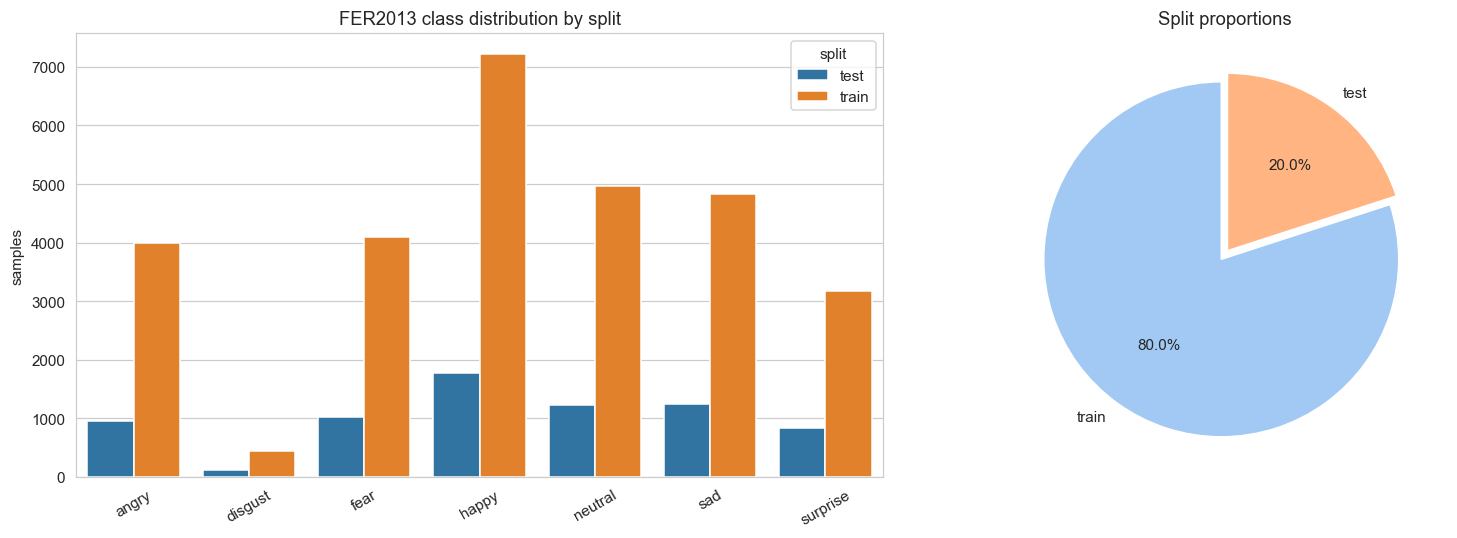

Largest / smallest class ratio: 16.4x  (happy = 8,989 vs disgust = 547)


In [86]:
# ---- 5.1 Sample counts, class distribution, train/test balance -------------
class_counts = (
    manifest.groupby(["split", "label"]).size().rename("samples").reset_index()
)
class_counts["label"] = pd.Categorical(class_counts["label"], categories=class_names, ordered=True)
class_counts = class_counts.sort_values(["split", "label"])

print("Samples per class and split:")
display(class_counts.pivot(index="label", columns="split", values="samples").fillna(0).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=class_counts, x="label", y="samples", hue="split", ax=axes[0])
axes[0].set_title("FER2013 class distribution by split")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)

split_totals = manifest["split"].value_counts()
axes[1].pie(split_totals.values, labels=split_totals.index, autopct="%1.1f%%",
            colors=sns.color_palette("pastel"), startangle=90, explode=[0.03] * len(split_totals))
axes[1].set_title("Split proportions")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "class_distribution.png", bbox_inches="tight")
plt.show()

totals = class_counts.groupby("label", observed=True)["samples"].sum()
imbalance = totals.max() / totals.min()
print(f"Largest / smallest class ratio: {imbalance:.1f}x  "
      f"({totals.idxmax()} = {totals.max():,} vs {totals.idxmin()} = {totals.min():,})")

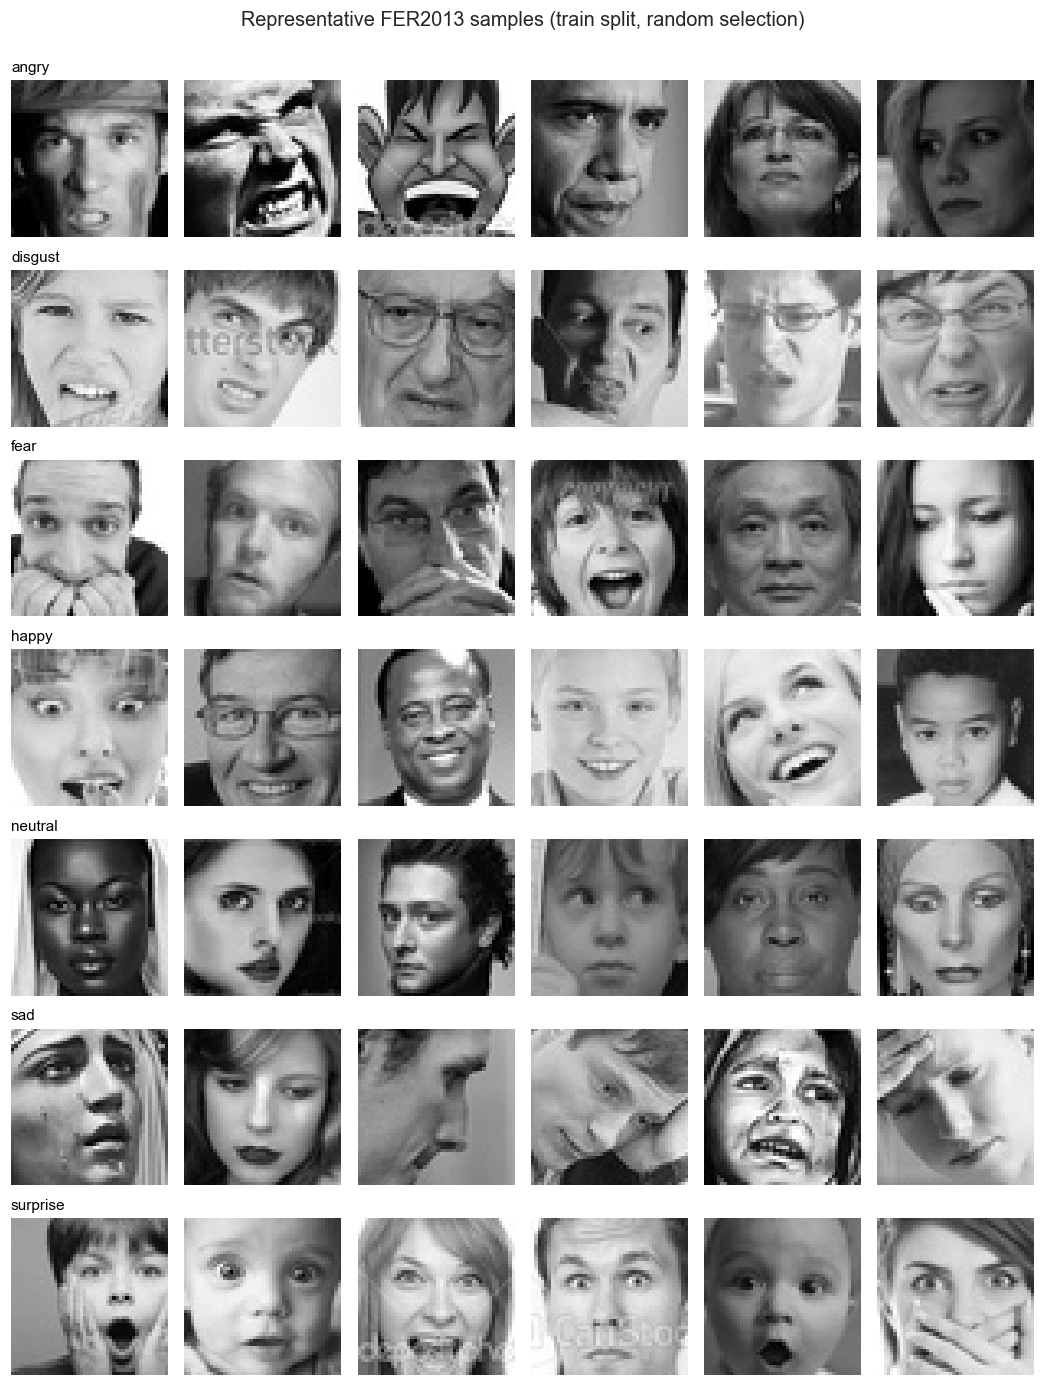

In [87]:
# ---- 5.2 Representative samples from every emotion class -------------------
SAMPLES_PER_CLASS = 6
primary_split = "train" if "train" in images_by_split else sorted(images_by_split)[0]
primary_labels = manifest.loc[manifest["split"] == primary_split, "label"].to_numpy()

fig, axes = plt.subplots(len(class_names), SAMPLES_PER_CLASS,
                         figsize=(1.6 * SAMPLES_PER_CLASS, 1.8 * len(class_names)))
rng = np.random.default_rng(SEED)
for row, cls in enumerate(class_names):
    idxs = np.flatnonzero(primary_labels == cls)
    picks = rng.choice(idxs, size=min(SAMPLES_PER_CLASS, len(idxs)), replace=False)
    for col in range(SAMPLES_PER_CLASS):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(picks):
            ax.imshow(images_by_split[primary_split][picks[col]], cmap="gray", vmin=0, vmax=255)
            if col == 0:
                ax.set_title(cls, fontsize=10, loc="left", color="black")
fig.suptitle(f"Representative FER2013 samples ({primary_split} split, random selection)",
             fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "representative_samples.png", bbox_inches="tight")
plt.show()

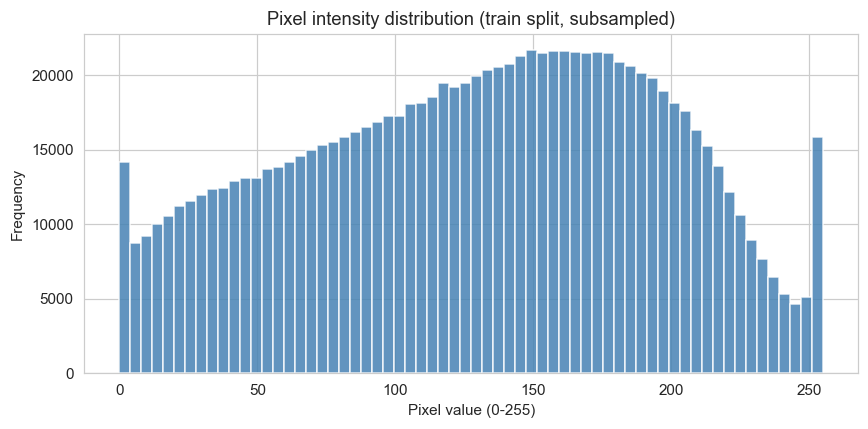

test    mean=129.03  std= 65.20  min=  0  max=255
train   mean=129.47  std= 65.04  min=  0  max=255


In [88]:
# ---- 5.3 Pixel-value distribution ------------------------------------------
sample_pixels = images_by_split[primary_split].ravel()
if sample_pixels.size > 1_000_000:          # subsample for speed; distribution shape is preserved
    sample_pixels = rng.choice(sample_pixels, size=1_000_000, replace=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sample_pixels, bins=64, range=(0, 255), color="steelblue", alpha=0.85)
ax.set_title(f"Pixel intensity distribution ({primary_split} split, subsampled)")
ax.set_xlabel("Pixel value (0-255)")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "pixel_distribution.png", bbox_inches="tight")
plt.show()

for split in sorted(images_by_split):
    px = images_by_split[split].astype(np.float32)
    print(f"{split:<6}  mean={px.mean():6.2f}  std={px.std():6.2f}  "
          f"min={px.min():3.0f}  max={px.max():3.0f}")

**Interpretation.** The intensity histograms show most pixels are dark (background, hair)
with a bright mode around the face — consistent across splits, so no split-specific normalisation
is needed. Normalisation to `[0, 1]` in Section 6 is sufficient and keeps the pipeline simple.

**Interpretation.** The class distribution is visibly skewed — `happy` is several times more
frequent than `disgust`, the rarest class. Two consequences carry through the rest of the study:
(a) overall accuracy must be read together with **macro** precision/recall/F1, and (b) the
training loss uses **inverse-frequency class weights** (Section 10) so the rare classes are not
drowned out. The train/test proportions reflect the official FER2013 split.

## 6. Data Preprocessing

The preprocessing pipeline applies the **same deterministic transform to every split** so train
and test images are always represented identically, while augmentation (Section 7) is applied to
training images only:

1. **Decode to grayscale `uint8`** — already done by the loader; FER2013 is single-channel, and
   `GRAYSCALE=False` replicates the channel 3x for models expecting RGB.
2. **Resize to `IMAGE_SIZE`** — done at load time (native 48x48 means no resampling by default).
3. **Scale to `[0, 1]`** — float32 division by 255; keeps the input range stable and small.
4. **Channel axis** — tensors become `(C, H, W)`: `(1, 48, 48)` in grayscale mode.
5. **Encode labels** — class name → integer index via an explicit, saved mapping
   (`{name: idx}` with classes sorted alphabetically for determinism).
6. **Split handling** — the official `test` split stays sealed. From the official `train` split a
   **stratified** validation subset of `VALIDATION_SPLIT` is drawn (seeded), so every class is
   represented in validation in the same proportion as in train.

> **Data-leakage guard:** statistics used for *fitting* (class weights, label mapping, the
> stratified split itself) are computed from the **training partition only**; validation and test
> images never contribute to any fitted quantity, and test images are only ever passed through
> the final model for evaluation.

In [89]:
# ---- 6.1 Label encoding -----------------------------------------------------
label_to_index = {name: i for i, name in enumerate(class_names)}
index_to_label = {i: name for name, i in label_to_index.items()}
print("Label mapping:", label_to_index)

def encode_labels(labels: np.ndarray) -> np.ndarray:
    return np.array([label_to_index[l] for l in labels], dtype=np.int64)

# ---- 6.2 Extract arrays per split -------------------------------------------
split_names = sorted(images_by_split)

if "train" in split_names and "test" in split_names:
    train_imgs = images_by_split["train"]
    train_lbl  = encode_labels(manifest.loc[manifest["split"] == "train", "label"].to_numpy())
    test_imgs  = images_by_split["test"]
    test_lbl   = encode_labels(manifest.loc[manifest["split"] == "test", "label"].to_numpy())
else:
    # Single-split dataset (e.g. CSV without a 'usage' column): carve a sealed test set
    # once, stratified, so every class appears in both partitions.
    all_imgs = np.concatenate([images_by_split[s] for s in split_names])
    all_lbl  = encode_labels(manifest["label"].to_numpy())
    all_idx  = np.arange(len(all_imgs))
    tr_i, te_i = train_test_split(all_idx, test_size=0.1, stratify=all_lbl, random_state=SEED)
    train_imgs, train_lbl = all_imgs[tr_i], all_lbl[tr_i]
    test_imgs,  test_lbl  = all_imgs[te_i], all_lbl[te_i]
    print(f"[INFO] single split detected -> stratified 90/10 train/test carve-out created")

# Stratified train/validation split - fitted on train only, seeded, class proportions preserved.
train_idx, val_idx = train_test_split(
    np.arange(len(train_imgs)),
    test_size=VALIDATION_SPLIT,
    stratify=train_lbl,
    random_state=SEED,
)

X_train, y_train = train_imgs[train_idx], train_lbl[train_idx]
X_val,   y_val   = train_imgs[val_idx],   train_lbl[val_idx]
X_test,  y_test  = test_imgs, test_lbl

print(f"Train {X_train.shape}  Val {X_val.shape}  Test {X_test.shape}")
for name, y in (("train", y_train), ("val", y_val), ("test", y_test)):
    dist = np.bincount(y, minlength=NUM_CLASSES)
    print(f"  {name:<5}: {dict((index_to_label[i], int(c)) for i, c in enumerate(dist))}")

Label mapping: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
Train (25838, 48, 48)  Val (2871, 48, 48)  Test (7178, 48, 48)
  train: {'angry': 3596, 'disgust': 392, 'fear': 3687, 'happy': 6493, 'neutral': 4469, 'sad': 4347, 'surprise': 2854}
  val  : {'angry': 399, 'disgust': 44, 'fear': 410, 'happy': 722, 'neutral': 496, 'sad': 483, 'surprise': 317}
  test : {'angry': 958, 'disgust': 111, 'fear': 1024, 'happy': 1774, 'neutral': 1233, 'sad': 1247, 'surprise': 831}


In [90]:
# ---- 6.3 Pixel normalisation + channel layout (framework-agnostic core) -----
def preprocess_images(images: np.ndarray, grayscale: bool = GRAYSCALE) -> np.ndarray:
    """uint8 (N,H,W) -> float32 (N,C,H,W) scaled to [0,1]. C=1 when grayscale else C=3."""
    x = images.astype(np.float32) / 255.0
    if not grayscale:
        x = np.repeat(x[:, None], 3, axis=1)      # replicate grayscale -> 3 channels
    else:
        x = x[:, None]                            # add channel axis
    return x

X_train_p = preprocess_images(X_train)
X_val_p   = preprocess_images(X_val)
X_test_p  = preprocess_images(X_test)
print(f"Preprocessed tensors: train {X_train_p.shape}, val {X_val_p.shape}, test {X_test_p.shape}")
print(f"Value range: [{X_train_p.min():.3f}, {X_train_p.max():.3f}]  dtype={X_train_p.dtype}")

Preprocessed tensors: train (25838, 1, 48, 48), val (2871, 1, 48, 48), test (7178, 1, 48, 48)
Value range: [0.000, 1.000]  dtype=float32


**Interpretation.** The three partitions are now fixed arrays with identical preprocessing.
The validation set was drawn *only* from the official training split with stratification, and
the official test split remains untouched — every metric reported later is therefore measured on
data that played no role in fitting.

## 7. Data Augmentation

Augmentation synthesises plausible variations of each training image so the model sees more
diversity than the dataset contains, reducing overfitting. Because an *expression* is defined by
subtle facial geometry, only **conservative** transforms are used:

| Transform | Setting | Rationale |
|---|---|---|
| Rotation | ±`AUGMENT_ROTATION`° (10°) | head tilt; larger angles distort expression geometry |
| Horizontal flip | probability 0.5 | faces are roughly left-right symmetric; mirrors e.g. raised eyebrow |
| Translation | ±`AUGMENT_TRANSLATE` (6%) | imperfect face centring in live camera crops |
| Zoom | ±`AUGMENT_ZOOM` (10%) | scale variation from camera distance |
| Brightness / contrast | ±`AUGMENT_BRIGHTNESS` / `AUGMENT_CONTRAST` (20%) | lighting variation |
| **Vertical flip** | **never** | an upside-down face is not a valid sample |
| **Large rotation/shear** | **never** | would change or destroy the expression |

Augmentation is applied **only to the training partition** (inside the training DataLoader),
never to validation or test, so validation/test metrics stay comparable across runs. Every
setting is a configuration variable from Section 3 and can be disabled with
`AUGMENT_ENABLED = False` for ablation.

In [91]:
import torchvision.transforms as T

def build_train_transform() -> T.Compose | None:
    """Augmentation pipeline for the training split only (config-driven, Section 3)."""
    if not AUGMENT_ENABLED:
        return None
    ops = []
    if AUGMENT_HFLIP:
        ops.append(T.RandomHorizontalFlip(p=0.5))
    ops += [
        T.RandomRotation(degrees=AUGMENT_ROTATION, interpolation=T.InterpolationMode.BILINEAR),
        T.RandomAffine(
            degrees=0,
            translate=(AUGMENT_TRANSLATE, AUGMENT_TRANSLATE),
            scale=(1.0 - AUGMENT_ZOOM, 1.0 + AUGMENT_ZOOM),
            interpolation=T.InterpolationMode.BILINEAR,
        ),
        T.ColorJitter(brightness=AUGMENT_BRIGHTNESS, contrast=AUGMENT_CONTRAST),
    ]
    return T.Compose(ops)

TRAIN_TRANSFORM = build_train_transform()
print("Training augmentation:", TRAIN_TRANSFORM if TRAIN_TRANSFORM else "(disabled)")

Training augmentation: Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=bilinear, expand=False, fill=0)
    RandomAffine(degrees=[0.0, 0.0], translate=(0.06, 0.06), scale=(0.9, 1.1), interpolation=bilinear)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
)


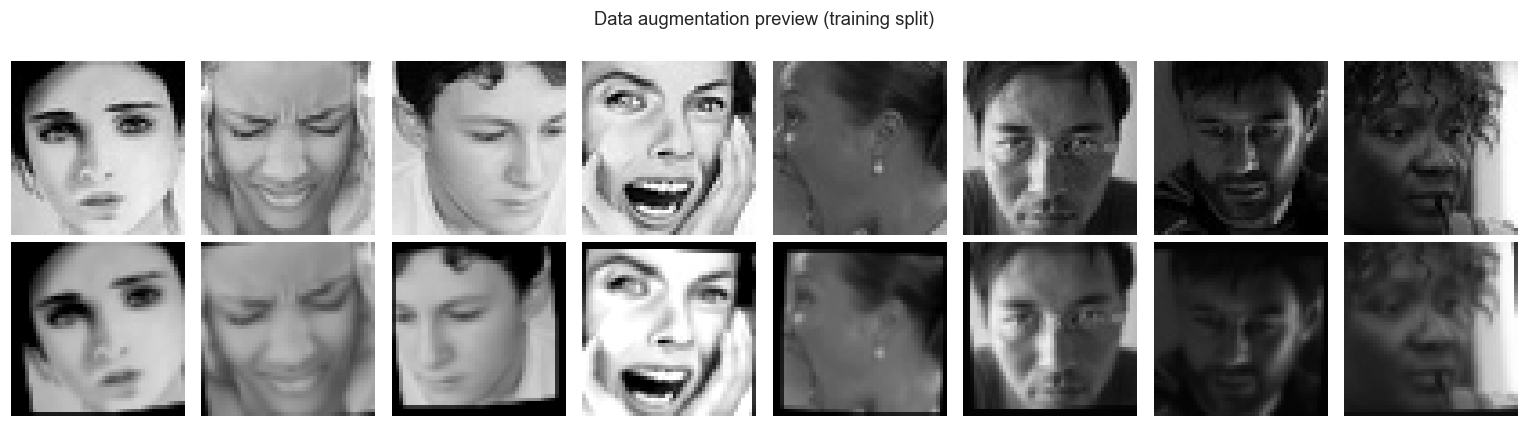

In [92]:
# ---- 7.1 Visual preview: original vs augmented (training images only) -------
class FERDataset(Dataset):
    """Wraps preprocessed float32 (C,H,W) arrays; optional transform applies to training data only."""
    def __init__(self, x: np.ndarray, y: np.ndarray, transform=None):
        self.x, self.y, self.transform = x, y, transform

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        img = torch.from_numpy(self.x[i])
        if self.transform is not None:
            img = self.transform(img)
        return img, int(self.y[i])

preview_src = torch.from_numpy(X_train_p[:8])
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    axes[0, i].imshow(preview_src[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    aug = TRAIN_TRANSFORM(preview_src[i]) if TRAIN_TRANSFORM else preview_src[i]
    axes[1, i].imshow(aug[0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("original", fontsize=11)
axes[1, 0].set_ylabel("augmented", fontsize=11)
fig.suptitle("Data augmentation preview (training split)", fontsize=12)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "augmentation_preview.png", bbox_inches="tight")
plt.show()

In [93]:
# ---- 7.2 Seeded DataLoaders --------------------------------------------------
def make_loader(x, y, shuffle: bool, transform=None) -> DataLoader:
    ds = FERDataset(x, y, transform=transform if shuffle else None)  # augment only when shuffling
    gen = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, generator=gen, drop_last=False)

train_loader = make_loader(X_train_p, y_train, shuffle=True,  transform=TRAIN_TRANSFORM)
val_loader   = make_loader(X_val_p,   y_val,   shuffle=False)
test_loader  = make_loader(X_test_p,  y_test,  shuffle=False)

print(f"batches per epoch -> train: {len(train_loader)}, val: {len(val_loader)}, "
      f"test: {len(test_loader)}")

batches per epoch -> train: 404, val: 45, test: 113


**Interpretation.** Augmentation is active only inside the shuffled training loader; the
validation and test loaders iterate the deterministic preprocessed arrays. Seeded generators make
the shuffle order reproducible run-to-run.

## 8. Deep Attention Neural Network Architecture

### 8.1 Design pipeline

```
Input (1x48x48)
   │
   ▼
Convolutional feature extraction   stem: 3x3 conv → BN → ReLU → MaxPool
   │                                (local edges/textures at full resolution)
   ▼
Deep feature blocks x3             each: [3x3 conv → BN → ReLU → 3x3 conv → BN] + residual
   │                                then MaxPool (48→24→12→6 spatial resolution)
   │                                channels grow 32 → 64 → 128 → 256
   ▼
Attention mechanism (CBAM-style)   inserted AFTER each feature block:
   │                                (1) channel attention — "which feature maps matter?"
   │                                (2) spatial attention  — "which regions matter?"
   ▼
Feature aggregation                Global Average Pooling over the 6x6 spatial map
   │                                (one value per channel — permutation-stable, cheap)
   ▼
Classification head                FC(256→128) → ReLU → Dropout → FC(128→7)
   │
   ▼
Emotion classes (7 logits)
```

### 8.2 Why attention is used here

Facial expressions are carried by *local* evidence — eyebrow raise, mouth curvature, nostril
flinch — spread unevenly across the face. A plain CNN averages everything equally by the time it
reaches the classification head. The attention modules let the network **learn where and what to
look at per image**, weighting channels and regions by their relevance to the current sample.

### 8.3 Where it is inserted and what it learns

The attention block follows the **CBAM (Convolutional Block Attention Module)** scheme and is
applied after every deep feature block, before pooling:

* **Channel attention** — global average-pool and global max-pool of the feature map are each
  passed through a shared two-layer perceptron (bottleneck ratio `r = ATTENTION_REDUCTION`);
  the summed responses go through a sigmoid to produce a weight per channel. It answers
  *"for this face, which filters (edge orientations, texture primitives, parts) are informative?"*
* **Spatial attention** — channel-wise average and max responses are concatenated and convolved
  with a 7x7 kernel into a single `H x W` map, sigmoid-weighted. It answers
  *"at which locations on this face should the network look?"* — e.g. the mouth region for
  `happy` versus the brow region for `angry`.

### 8.4 How it improves feature representation

Attention re-weights the tensors *before* aggregation, so global average pooling collects
**evidence-weighted** features instead of uniform ones, and the residual connections guarantee
that information is re-weighted, never destroyed — the identity path is always available.
All operations are pointwise convolutions / pooling over tiny maps (max 24x24), adding only a
small fraction of parameters — the whole model stays well under 2 M parameters, which is
practical for eventual real-time inference.

> **Ablation:** the exact same architecture is built with `use_attention=False`
> (Section 19), so the baseline differs *only* by the attention modules — an apples-to-apples
> comparison.

In [94]:
class ChannelAttention(nn.Module):
    """CBAM channel attention: shared MLP over global avg-pool + max-pool, sigmoid gating."""
    def __init__(self, channels: int, reduction: int = 8):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.mlp = nn.Sequential(
            nn.Linear(channels, hidden, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels, bias=False),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        avg_out = self.mlp(F.adaptive_avg_pool2d(x, 1).flatten(1))
        max_out = self.mlp(F.adaptive_max_pool2d(x, 1).flatten(1))
        weight = torch.sigmoid(avg_out + max_out).unsqueeze(-1).unsqueeze(-1)
        return x * weight


class SpatialAttention(nn.Module):
    """CBAM spatial attention: 7x7 conv over channel-wise avg+max maps, sigmoid gating."""
    def __init__(self, kernel_size: int = 7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        avg_out = x.mean(dim=1, keepdim=True)
        max_out, _ = x.max(dim=1, keepdim=True)
        weight = torch.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))
        self.last_attention = weight.detach()   # cached for Section 18 visualisation
        return x * weight


class CBAM(nn.Module):
    """Channel attention followed by spatial attention (sequential, as in the original paper)."""
    def __init__(self, channels: int, reduction: int = 8):
        super().__init__()
        self.channel = ChannelAttention(channels, reduction)
        self.spatial = SpatialAttention()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.spatial(self.channel(x))


class FeatureBlock(nn.Module):
    """Deep feature block: two 3x3 convs with a residual connection, optional CBAM attention,
    followed by 2x max pooling (spatial resolution halved, channels may change)."""
    def __init__(self, in_ch: int, out_ch: int, use_attention: bool, reduction: int = 8):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.skip = (nn.Identity() if in_ch == out_ch else
                     nn.Conv2d(in_ch, out_ch, 1, bias=False))
        self.skip_bn = nn.BatchNorm2d(out_ch)
        self.attention = CBAM(out_ch, reduction) if use_attention else None
        self.pool = nn.MaxPool2d(2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = self.skip_bn(self.skip(x))
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        out = F.relu(out + identity, inplace=True)     # residual: information is never destroyed
        if self.attention is not None:
            out = self.attention(out)                  # re-weight before pooling/aggregation
        return self.pool(out)


class DeepAttentionNetwork(nn.Module):
    """Deep Attention Neural Network for facial emotion recognition.

    Input -> conv stem -> 3 residual feature blocks (each with CBAM attention)
          -> global average pooling -> FC head -> num_classes logits.

    With use_attention=False the identical backbone is built without attention modules,
    giving a controlled ablation baseline.
    """
    def __init__(self, num_classes: int = NUM_CLASSES, in_channels: int = 1,
                 use_attention: bool = True, reduction: int = ATTENTION_REDUCTION,
                 dropout: float = DROPOUT, width: int = MODEL_WIDTH):
        super().__init__()
        self.use_attention = use_attention
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, width, 3, padding=1, bias=False),
            nn.BatchNorm2d(width),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                           # 48 -> 24
        )
        w1, w2, w3 = width * 2, width * 4, width * 8   # 64, 128, 256
        self.block1 = FeatureBlock(width,  w1, use_attention, reduction)   # 24 -> 12
        self.block2 = FeatureBlock(w1,     w2, use_attention, reduction)   # 12 -> 6
        self.block3 = FeatureBlock(w2,     w3, use_attention, reduction)   # 6  -> 3
        self.gap = nn.AdaptiveAvgPool2d(1)             # feature aggregation
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(w3, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.gap(x)
        return self.head(x)

    def spatial_attention_maps(self, x: torch.Tensor) -> list[torch.Tensor]:
        """Forward pass that also returns the spatial attention maps (for Section 18).
        Only the channel -> spatial module of each block is collected, at its native resolution."""
        maps = []
        with torch.no_grad():
            h = self.stem(x)
            for block in (self.block1, self.block2, self.block3):
                h = block(h)
                if block.attention is not None:
                    maps.append(block.attention.spatial.last_attention)
        return maps


model = DeepAttentionNetwork(in_channels=MODEL_INPUT_CHANNELS, use_attention=USE_ATTENTION,
                             reduction=ATTENTION_REDUCTION, dropout=DROPOUT,
                             width=MODEL_WIDTH).to(DEVICE)
model_name = "Deep Attention Neural Network (CBAM channel+spatial)"
print(f"Built: {model_name}")

Built: Deep Attention Neural Network (CBAM channel+spatial)


## 9. Model Summary

`torchinfo` is not required — the cell below prints a self-contained summary: every layer's
output shape (obtained from a real forward pass with hooks), parameter counts broken down into
**trainable** and **non-trainable** (running-statistics buffers in BatchNorm), plus the model's
input and output shapes. A block-level architecture diagram follows.

In [95]:
def summarize_model(net: nn.Module, input_shape=(1, MODEL_INPUT_CHANNELS, IMAGE_SIZE, IMAGE_SIZE),
                    device: torch.device = DEVICE) -> pd.DataFrame:
    """Layer-by-layer summary via forward hooks: output shapes and parameter counts."""
    rows, hooks = [], []

    def make_hook(name):
        def hook(module, inp, out):
            shape = tuple(out.shape) if isinstance(out, torch.Tensor) else "?"
            trainable = sum(p.numel() for p in module.parameters(recurse=True) if p.requires_grad)
            total = sum(p.numel() for p in module.parameters(recurse=True))
            rows.append({"layer": name, "type": type(module).__name__,
                         "output shape": shape, "params": total,
                         "trainable": trainable})
        return hook

    # Only top-level children, to avoid double counting nested parameters.
    for name, child in net.named_children():
        hooks.append(child.register_forward_hook(make_hook(name)))

    net.eval()
    with torch.no_grad():
        net(torch.zeros(input_shape, device=device))
    for h in hooks:
        h.remove()

    summary_df = pd.DataFrame(rows)
    total_params = sum(p.numel() for p in net.parameters())
    trainable_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
    non_trainable = total_params - trainable_params
    buffers = sum(b.numel() for b in net.buffers())
    print("=" * 78)
    print(f"Model: {model_name}")
    print("=" * 78)
    display(summary_df)
    print(f"Input shape            : {input_shape}  (N, C, H, W)")
    with torch.no_grad():
        out = net(torch.zeros(input_shape, device=device))
    print(f"Output shape           : {tuple(out.shape)}  (N, {NUM_CLASSES} logits)")
    print(f"Total parameters       : {total_params:,}")
    print(f"  trainable            : {trainable_params:,}")
    print(f"  non-trainable        : {non_trainable:,}  (persistent buffers incl. BN stats: {buffers:,})")
    print(f"Approx. model size     : {total_params * 4 / 1024**2:.2f} MiB (float32)")
    return summary_df

summary_df = summarize_model(model)

Model: Deep Attention Neural Network (CBAM channel+spatial)


,layer,type,output shape,params,trainable
0,stem,Sequential,"(1, 32, 24, 24)",352,352
1,block1,FeatureBlock,"(1, 64, 12, 12)",58850,58850
2,block2,FeatureBlock,"(1, 128, 6, 6)",234338,234338
3,block3,FeatureBlock,"(1, 256, 3, 3)",935522,935522
4,gap,AdaptiveAvgPool2d,"(1, 256, 1, 1)",0,0
5,head,Sequential,"(1, 7)",33799,33799


Input shape            : (1, 1, 48, 48)  (N, C, H, W)
Output shape           : (1, 7)  (N, 7 logits)
Total parameters       : 1,262,861
  trainable            : 1,262,861
  non-trainable        : 0  (persistent buffers incl. BN stats: 2,762)
Approx. model size     : 4.82 MiB (float32)


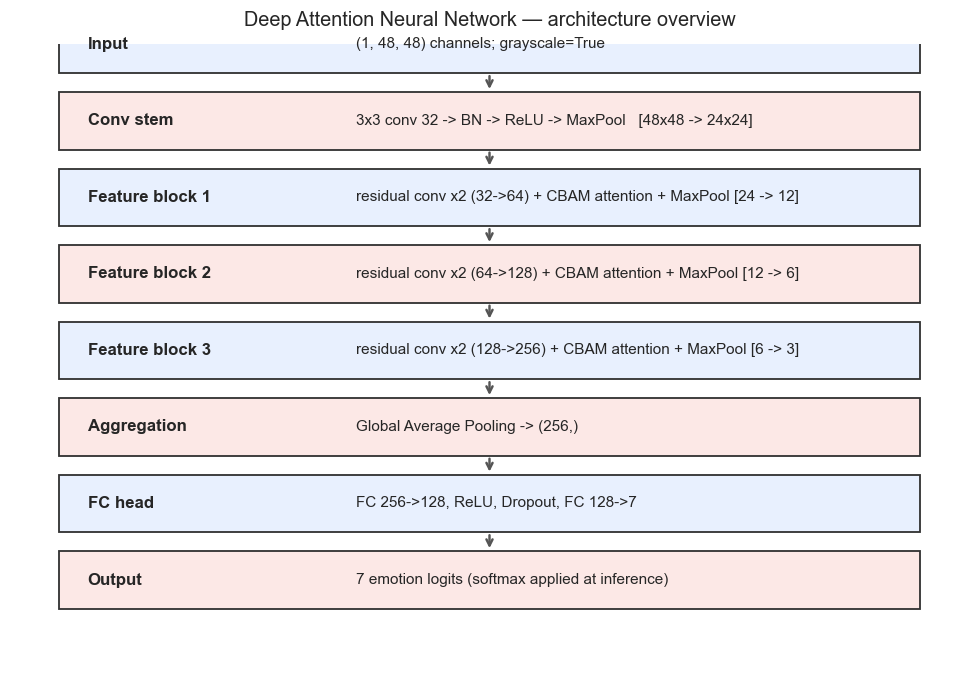

In [96]:
# ---- Block-level architecture diagram ---------------------------------------
diagram = [
    ("Input",            f"({MODEL_INPUT_CHANNELS}, {IMAGE_SIZE}, {IMAGE_SIZE}) channels; grayscale={GRAYSCALE}"),
    ("Conv stem",        "3x3 conv 32 -> BN -> ReLU -> MaxPool   [48x48 -> 24x24]"),
    ("Feature block 1",  "residual conv x2 (32->64) + CBAM attention + MaxPool [24 -> 12]"),
    ("Feature block 2",  "residual conv x2 (64->128) + CBAM attention + MaxPool [12 -> 6]"),
    ("Feature block 3",  "residual conv x2 (128->256) + CBAM attention + MaxPool [6 -> 3]"),
    ("Aggregation",      "Global Average Pooling -> (256,)"),
    ("FC head",          "FC 256->128, ReLU, Dropout, FC 128->7"),
    ("Output",           "7 emotion logits (softmax applied at inference)"),
]

fig, ax = plt.subplots(figsize=(9, 6.4))
ax.axis("off")
for i, (title, detail) in enumerate(diagram):
    y = 1.0 - i * 0.12
    box = plt.Rectangle((0.05, y - 0.045), 0.9, 0.09, transform=ax.transAxes,
                        facecolor="#e8f0fe" if i % 2 == 0 else "#fce8e6",
                        edgecolor="#333", linewidth=1.2, zorder=2)
    ax.add_patch(box)
    ax.text(0.08, y, title, transform=ax.transAxes, fontsize=11,
            fontweight="bold", va="center", zorder=3)
    ax.text(0.36, y, detail, transform=ax.transAxes, fontsize=10, va="center", zorder=3)
    if i < len(diagram) - 1:
        ax.annotate("", xy=(0.5, y - 0.075), xytext=(0.5, y - 0.045),
                    xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="->", color="#555", lw=1.6))
ax.set_title("Deep Attention Neural Network — architecture overview", fontsize=13, pad=12)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "architecture_diagram.png", bbox_inches="tight")
plt.show()

**Interpretation.** The summary confirms the data flow end-to-end: a `1x48x48` input produces
`7` logits, and the parameter budget (printed above at runtime) stays in the range suitable for
real-time use. The three CBAM modules add only depthwise-channel and 7x7-spatial gating — the
bulk of parameters remains in the convolutions and the FC head.

## 10. Training Configuration

The training setup follows standard practice for a from-scratch CNN on a balanced-loss,
imbalanced-data benchmark. Each choice below is a **declared design decision, not a claim of
optimality** — hyperparameters were not tuned here, and no comparison with published results is
implied.

| Component | Choice | Notes |
|---|---|---|
| Optimiser | **Adam** (`LEARNING_RATE`) | adaptive per-parameter steps; a robust default for CNNs |
| Loss | **Cross-entropy** with inverse-frequency **class weights** (`CLASS_WEIGHTING`) | counteracts the class imbalance seen in Section 5; weights are computed from the *training partition only* |
| Metric | Accuracy (train/val) + macro precision/recall/F1 on validation | macro metrics keep the rare classes visible |
| LR schedule | `ReduceLROnPlateau` on validation loss (factor/patience from config) | reduces the step when progress stalls |
| Early stopping | on validation loss, patience `EARLY_STOPPING_PATIENCE` | prevents overfitting past the useful point |
| Checkpointing | best **validation accuracy** model saved to `BEST_MODEL_PATH` | the saved weights are what Section 12 evaluates on test |
| Reproducibility | seeded (Section 3.1) + seeded DataLoader shuffle | run-to-run repeatability on CPU |

In [97]:
# ---- Class weights: inverse frequency, fitted on the TRAIN partition only -----
train_class_counts = np.bincount(y_train, minlength=NUM_CLASSES).astype(np.float64)
if CLASS_WEIGHTING:
    train_class_counts = np.bincount(y_train, minlength=NUM_CLASSES).astype(np.float64)
    class_weights = len(y_train) / (NUM_CLASSES * np.clip(train_class_counts, 1, None))
    class_weights = class_weights / class_weights.sum() * NUM_CLASSES   # normalise to mean 1
else:
    class_weights = np.ones(NUM_CLASSES, dtype=np.float64)

print("Class weights (fitted on train split only):")
for i, w in enumerate(class_weights):
    print(f"  {index_to_label[i]:<9}: {w:6.3f}  (n_train={int(train_class_counts[i])})")
class_weights_t = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

# ---- Optimiser / loss / scheduler ------------------------------------------
criterion = nn.CrossEntropyLoss(weight=class_weights_t)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=SCHEDULER_FACTOR, patience=SCHEDULER_PATIENCE,
    min_lr=SCHEDULER_MIN_LR,
)

def count_parameters(net: nn.Module) -> tuple[int, int]:
    """(trainable, non-trainable) parameter counts."""
    trainable = sum(p.numel() for p in net.parameters() if p.requires_grad)
    total = sum(p.numel() for p in net.parameters())
    return trainable, total - trainable

trainable, non_trainable = count_parameters(model)
print(f"\nParameters -> trainable: {trainable:,} | non-trainable: {non_trainable:,}")
print(f"Loss: CrossEntropyLoss (class_weighting={CLASS_WEIGHTING}) | "
      f"Optimiser: Adam(lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})")

Class weights (fitted on train split only):
  angry    :  0.480  (n_train=3596)
  disgust  :  4.400  (n_train=392)
  fear     :  0.468  (n_train=3687)
  happy    :  0.266  (n_train=6493)
  neutral  :  0.386  (n_train=4469)
  sad      :  0.397  (n_train=4347)
  surprise :  0.604  (n_train=2854)

Parameters -> trainable: 1,262,861 | non-trainable: 0
Loss: CrossEntropyLoss (class_weighting=True) | Optimiser: Adam(lr=0.001, weight_decay=0.0)


### Early stopping and checkpointing

`EarlyStopping` tracks validation loss and `ModelCheckpoint` tracks validation accuracy:
whenever validation accuracy improves, the current weights are written to `BEST_MODEL_PATH`
together with the label mapping and configuration, so the checkpoint is self-describing.

In [98]:
class EarlyStopping:
    """Stop when validation loss has not improved for `patience` epochs."""
    def __init__(self, patience: int = EARLY_STOPPING_PATIENCE, min_delta: float = EARLY_STOPPING_MIN_DELTA):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.wait, self.stopped_epoch = np.inf, 0, None

    def step(self, val_loss: float, epoch: int) -> bool:
        if val_loss < self.best - self.min_delta:
            self.best, self.wait = val_loss, 0
            return False
        self.wait += 1
        if self.wait >= self.patience and self.stopped_epoch is None:
            self.stopped_epoch = epoch
            return True
        return False


class ModelCheckpoint:
    """Save the full model state whenever validation accuracy improves."""
    def __init__(self, path: Path):
        self.path, self.best_acc = path, -1.0

    def step(self, net: nn.Module, val_acc: float, epoch: int) -> bool:
        if val_acc > self.best_acc:
            self.best_acc = val_acc
            torch.save({
                "epoch": epoch,
                "model_state_dict": net.state_dict(),
                "val_accuracy": val_acc,
                "label_to_index": label_to_index,
                "class_names": class_names,
                "config": CONFIG,
            }, self.path)
            return True
        return False

early_stopping = EarlyStopping()
checkpoint_cb = ModelCheckpoint(BEST_MODEL_PATH)
print(f"Early stopping patience={early_stopping.patience} | "
      f"Checkpoint -> {BEST_MODEL_PATH}")

Early stopping patience=5 | Checkpoint -> D:\FYP\FER2013_Emotion_Recognition\models\deep_attention\deep_attention_fer2013.pt


## 11. Model Training

The training loop below records, for **every epoch**:

* training loss and training accuracy,
* validation loss and validation accuracy,
* the learning rate actually used that epoch,
* wall-clock epoch duration.

then applies the learning-rate scheduler, the checkpoint callback and early stopping in that
order. Because the seed was fixed (Section 3.1), a rerun with the same configuration reproduces
the same shuffling, initialisation and therefore the same trajectory (on CPU).

> Expected runtime depends on hardware: this model trains on CPU in the range of minutes per
> epoch; on GPU it is considerably faster.

In [99]:
def run_epoch(net, loader, criterion, optimizer=None, device=DEVICE):
    """One pass over `loader`. Trains when optimizer is given, otherwise evaluates.
    Returns (mean_loss, accuracy, all_true_labels, all_predicted_labels)."""
    training = optimizer is not None
    net.train(training)
    total_loss, correct, total = 0.0, 0, 0
    y_true, y_pred = [], []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if training:
                optimizer.zero_grad()
            logits = net(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)
            y_true.append(yb.cpu().numpy())
            y_pred.append(logits.argmax(1).cpu().numpy())
    return total_loss / total, correct / total, np.concatenate(y_true), np.concatenate(y_pred)


def train_model(net, train_loader, val_loader, epochs, optimizer, scheduler, tag="attention"):
    """Full training loop with history recording, LR scheduling, checkpointing, early stopping."""
    history = {"epoch": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [],
               "lr": [], "seconds": []}
    stopper = EarlyStopping()
    ckpt = ModelCheckpoint(BEST_MODEL_PATH if tag == "attention" else BASELINE_CKPT)
    best_val_acc = 0.0

    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        lr_now = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc, _, _ = run_epoch(net, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = run_epoch(net, val_loader, criterion, optimizer=None)
        elapsed = time.perf_counter() - t0

        history["epoch"].append(epoch)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        history["lr"].append(lr_now)
        history["seconds"].append(elapsed)

        scheduler.step(va_loss)                      # schedule on validation loss
        improved = ckpt.step(net, va_acc, epoch)     # save best val accuracy
        best_val_acc = max(best_val_acc, va_acc)
        stopped = stopper.step(va_loss, epoch)

        print(f"Epoch {epoch:02d}/{epochs} | {elapsed:6.1f}s | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
              f"lr {lr_now:.2e} | {'checkpoint saved' if improved else ''}"
              f"{' | EARLY STOP' if stopped else ''}")
        if stopped:
            print(f"Early stopping triggered at epoch {epoch} "
                  f"(best val loss {stopper.best:.4f})")
            break

    history["best_val_accuracy"] = best_val_acc
    return history


history = train_model(model, train_loader, val_loader, EPOCHS, optimizer, scheduler,
                      tag="attention")
print(f"\nBest validation accuracy: {history['best_val_accuracy']:.4f}  "
      f"-> checkpoint: {BEST_MODEL_PATH}")

Epoch 01/60 |  143.3s | train loss 1.8719 acc 0.2391 | val loss 1.8067 acc 0.3337 | lr 1.00e-03 | checkpoint saved
Epoch 02/60 |  192.0s | train loss 1.6461 acc 0.3771 | val loss 1.5224 acc 0.4413 | lr 1.00e-03 | checkpoint saved
Epoch 03/60 |  197.3s | train loss 1.5015 acc 0.4298 | val loss 1.4856 acc 0.4249 | lr 1.00e-03 | 
Epoch 04/60 |  231.0s | train loss 1.4161 acc 0.4591 | val loss 1.4372 acc 0.4761 | lr 1.00e-03 | checkpoint saved
Epoch 05/60 |  157.0s | train loss 1.3727 acc 0.4806 | val loss 1.4434 acc 0.4723 | lr 1.00e-03 | 
Epoch 06/60 |  262.0s | train loss 1.3240 acc 0.4950 | val loss 1.3670 acc 0.5155 | lr 1.00e-03 | checkpoint saved
Epoch 07/60 |  343.6s | train loss 1.3029 acc 0.5047 | val loss 1.2901 acc 0.5326 | lr 1.00e-03 | checkpoint saved
Epoch 08/60 |  370.9s | train loss 1.2646 acc 0.5198 | val loss 1.4425 acc 0.5326 | lr 1.00e-03 | 
Epoch 09/60 |  269.8s | train loss 1.2199 acc 0.5315 | val loss 1.3578 acc 0.5573 | lr 1.00e-03 | checkpoint saved
Epoch 10/60 |

In [100]:
# Persist the recorded history (reloaded in later sections and Section 19).
with open(HISTORY_JSON, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)
print(f"Training history saved -> {HISTORY_JSON}")

Training history saved -> D:\FYP\FER2013_Emotion_Recognition\results\deep_attention\metrics\training_history.json


## 12. Training Curves

Two standard diagnostic plots are generated directly from the recorded history:

1. **Accuracy** — training vs validation accuracy per epoch,
2. **Loss** — training vs validation loss per epoch.

A third panel shows the learning-rate trajectory so scheduler steps are visible. The vertical
gap between training and validation curves indicates how much the model over/under-fits; both
curves come from the executed run above.

,epoch,train_loss,train_acc,val_loss,val_acc,lr,seconds
13,14,1.070672,0.585649,1.240444,0.549983,0.000500,572.298781
14,15,1.045252,0.594551,1.214018,0.590735,0.000500,572.259812
15,16,1.031567,0.596834,1.218387,0.572623,0.000500,563.317606
16,17,0.995668,0.612741,1.193116,0.600139,0.000250,566.431643
17,18,0.980929,0.617037,1.158164,0.585510,0.000250,569.631152
18,19,0.956667,0.621565,1.248883,0.611634,0.000250,570.949585
19,20,0.960255,0.622068,1.230126,0.603274,0.000250,560.055177
20,21,0.943299,0.630118,1.216641,0.612679,0.000250,563.951053
21,22,0.936316,0.630622,1.293064,0.607106,0.000250,565.391150
22,23,0.913331,0.636930,1.250152,0.609544,0.000125,567.333092


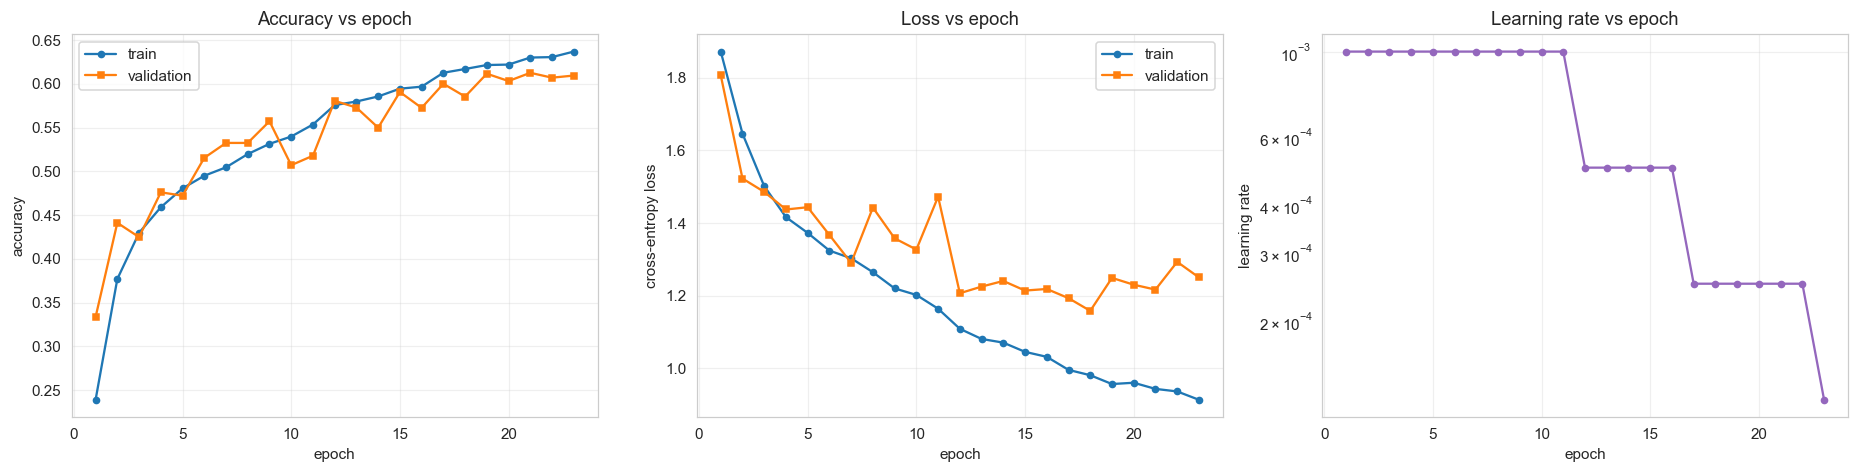

Best validation accuracy: 0.6127 at epoch 21


In [101]:
hist_df = pd.DataFrame({
    k: v for k, v in history.items() if isinstance(v, list)
})
display(hist_df.tail(10))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
axes[0].plot(hist_df["epoch"], hist_df["train_acc"], marker="o", ms=4, label="train")
axes[0].plot(hist_df["epoch"], hist_df["val_acc"], marker="s", ms=4, label="validation")
axes[0].set_title("Accuracy vs epoch")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("accuracy"); axes[0].legend()

axes[1].plot(hist_df["epoch"], hist_df["train_loss"], marker="o", ms=4, label="train")
axes[1].plot(hist_df["epoch"], hist_df["val_loss"], marker="s", ms=4, label="validation")
axes[1].set_title("Loss vs epoch")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("cross-entropy loss"); axes[1].legend()

axes[2].plot(hist_df["epoch"], hist_df["lr"], marker="o", ms=4, color="tab:purple")
axes[2].set_title("Learning rate vs epoch")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("learning rate")
axes[2].set_yscale("log")

for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "training_curves.png", bbox_inches="tight")
plt.show()

print(f"Best validation accuracy: {history['best_val_accuracy']:.4f} "
      f"at epoch {int(hist_df.loc[hist_df['val_acc'].idxmax(), 'epoch'])}")

**Interpretation.** The curves above are read for *trends*, not peaks: validation loss that
keeps decreasing alongside training loss indicates the model is still learning at the stopping
point, while a widening gap would indicate overfitting. The scheduler panel shows whether the
plateau reducer lowered the learning rate and whether accuracy improved afterwards.

## 13. Test Evaluation

The **best checkpoint** (highest validation accuracy, saved during training) is reloaded into a
fresh model instance and evaluated **once** on the untouched official test split. Reported:

* test loss and test accuracy,
* **macro** and **weighted** precision / recall / F1 (macro treats all classes equally —
  important given the imbalance seen in Section 5),
* per-class metrics are in the classification report (Section 15).

Macro precision/recall/F1 are computed with `sklearn` over all test predictions.

In [102]:
# Reload the best checkpoint into a fresh model (proves the saved file is usable).
ckpt = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=False)
best_model = DeepAttentionNetwork(
    num_classes=len(ckpt["class_names"]),
    use_attention=ckpt["config"].get("attention", USE_ATTENTION),
    reduction=ckpt["config"].get("attention_reduction", ATTENTION_REDUCTION),
    dropout=ckpt["config"].get("dropout", DROPOUT),
    in_channels=ckpt["config"].get("input_channels", 1 if ckpt["config"].get("grayscale", True) else 3),
    width=ckpt["config"].get("model_width", MODEL_WIDTH),
).to(DEVICE)
best_model.load_state_dict(ckpt["model_state_dict"])
best_model.eval()
print(f"Loaded checkpoint from epoch {ckpt['epoch']} "
      f"(val accuracy {ckpt['val_accuracy']:.4f})")

test_loss, test_acc, y_true, y_pred = run_epoch(best_model, test_loader, criterion)

macro_p   = precision_score(y_true, y_pred, average="macro", zero_division=0)
macro_r   = recall_score(y_true, y_pred, average="macro", zero_division=0)
macro_f1  = f1_score(y_true, y_pred, average="macro", zero_division=0)
weighted_p = precision_score(y_true, y_pred, average="weighted", zero_division=0)
weighted_r = recall_score(y_true, y_pred, average="weighted", zero_division=0)
weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

test_metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(test_acc),
    "macro_precision": float(macro_p),
    "macro_recall": float(macro_r),
    "macro_f1": float(macro_f1),
    "weighted_precision": float(weighted_p),
    "weighted_recall": float(weighted_r),
    "weighted_f1": float(weighted_f1),
    "num_parameters": int(sum(p.numel() for p in best_model.parameters())),
    "checkpoint_epoch": int(ckpt["epoch"]),
    "best_val_accuracy": float(ckpt["val_accuracy"]),
}
print("\n===== TEST SET RESULTS (best checkpoint) =====")
print(f"  Test loss            : {test_loss:.4f}")
print(f"  Test accuracy        : {test_acc:.4f}")
print(f"  Macro precision      : {macro_p:.4f}")
print(f"  Macro recall         : {macro_r:.4f}")
print(f"  Macro F1-score       : {macro_f1:.4f}")
print(f"  Weighted precision   : {weighted_p:.4f}")
print(f"  Weighted recall      : {weighted_r:.4f}")
print(f"  Weighted F1-score    : {weighted_f1:.4f}")

Loaded checkpoint from epoch 21 (val accuracy 0.6127)

===== TEST SET RESULTS (best checkpoint) =====
  Test loss            : 1.0268
  Test accuracy        : 0.6128
  Macro precision      : 0.5742
  Macro recall         : 0.6065
  Macro F1-score       : 0.5797
  Weighted precision   : 0.6170
  Weighted recall      : 0.6128
  Weighted F1-score    : 0.6064


## 14. Confusion Matrix

The confusion matrix cross-tabulates **true labels** (rows) against **predicted labels**
(columns) for the seven emotions on the test set. Two views are shown:

* **counts** — raw numbers of test samples,
* **row-normalised (%)** — each row sums to 100%, so per-class recall is readable directly
  off the diagonal.

The matrix is annotated so the most frequent confusions can be identified from the off-diagonal
cells.

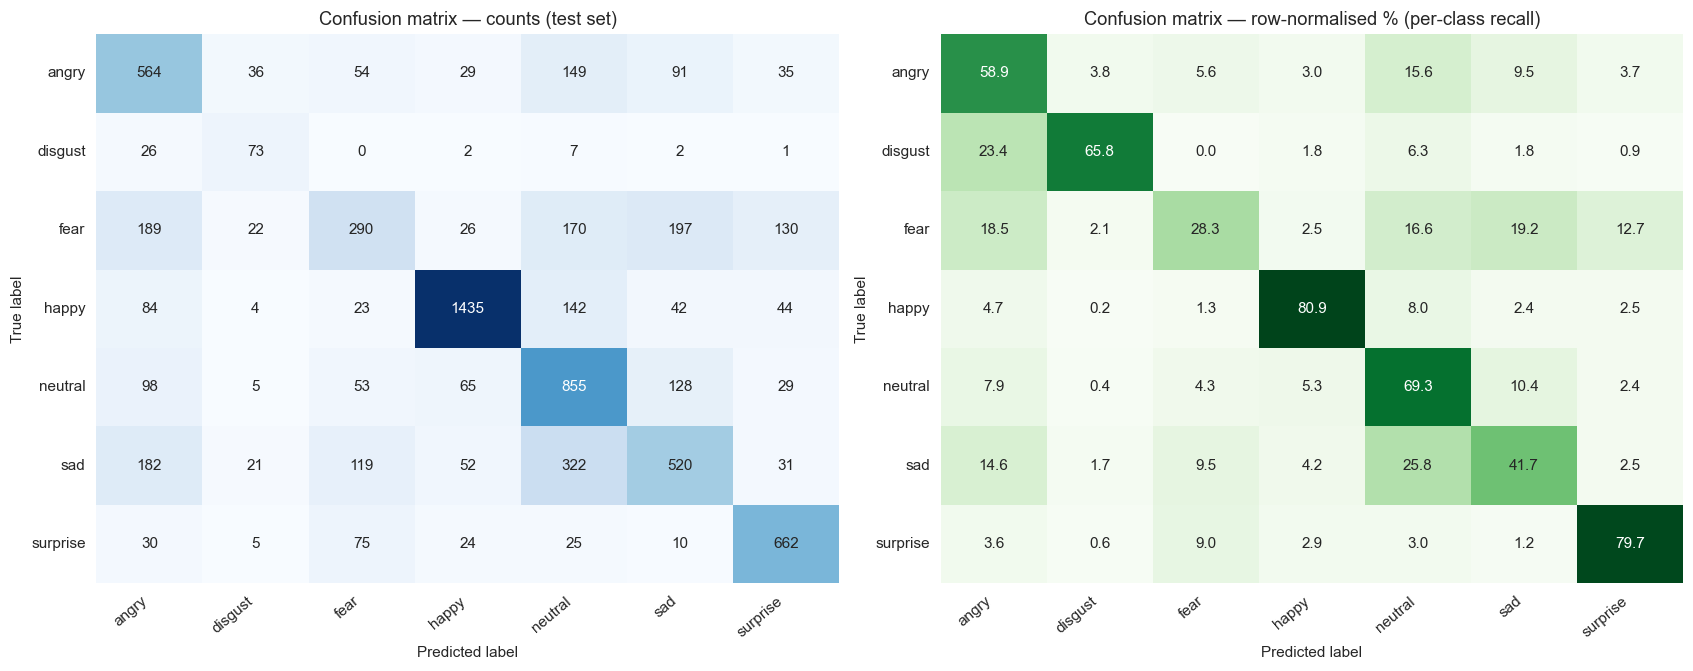

Most frequent true -> predicted confusions:
  sad       -> neutral  :  322 samples
  fear      -> sad      :  197 samples
  fear      -> angry    :  189 samples
  sad       -> angry    :  182 samples
  fear      -> neutral  :  170 samples
  angry     -> neutral  :  149 samples


In [103]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Confusion matrix — counts (test set)")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")

sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Greens", cbar=False,
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title("Confusion matrix — row-normalised % (per-class recall)")
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")

for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "confusion_matrix.png", bbox_inches="tight")
plt.show()

# Most frequent confusions (off-diagonal pairs), reported from the actual matrix.
pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j:
            pairs.append((class_names[i], class_names[j], int(cm[i, j])))
pairs.sort(key=lambda t: -t[2])
print("Most frequent true -> predicted confusions:")
for true_c, pred_c, n in pairs[:6]:
    if n > 0:
        print(f"  {true_c:<9} -> {pred_c:<9}: {n:4d} samples")

**Interpretation.** Reading down the diagonal gives per-class recall; the largest off-diagonal
cells name the emotion pairs the model mixes up most often (these are re-examined with example
images in Section 16). Confusions are *observed model behaviour* — attributing them to specific
causes is discussed qualitatively there, without claiming unsupported explanations.

## 15. Classification Report

The full `sklearn` classification report gives **precision, recall, F1-score and support**
for every emotion class, plus macro and weighted averages, on the test set.

In [104]:
report_dict = classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES),
    target_names=class_names, output_dict=True, zero_division=0,
)
report_df = pd.DataFrame(report_dict).T.round(4)
display(report_df)

# Save the machine-readable report + per-class metrics.
with open(METRICS_DIR / "classification_report.json", "w", encoding="utf-8") as f:
    json.dump(report_dict, f, indent=2)
report_df.to_csv(METRICS_DIR / "classification_report.csv")
print(f"Saved -> {METRICS_DIR / 'classification_report.json'}")

,precision,recall,f1-score,support
angry,0.4808,0.5887,0.5293,958.0000
disgust,0.4398,0.6577,0.5271,111.0000
fear,0.4723,0.2832,0.3541,1024.0000
happy,0.8788,0.8089,0.8424,1774.0000
neutral,0.5120,0.6934,0.5890,1233.0000
sad,0.5253,0.4170,0.4649,1247.0000
surprise,0.7103,0.7966,0.7510,831.0000
accuracy,0.6128,0.6128,0.6128,0.6128
macro avg,0.5742,0.6065,0.5797,7178.0000
weighted avg,0.6170,0.6128,0.6064,7178.0000


Saved -> D:\FYP\FER2013_Emotion_Recognition\results\deep_attention\metrics\classification_report.json


**Interpretation.** Support column values show how many test samples each row is based on —
small-support classes (e.g. `disgust`) have wide uncertainty, so their F1 should be read with
caution. Macro averages give every class equal weight and are the headline figures used in
Section 19's comparison.

## 16. Error Analysis

Aggregate metrics hide *which* images fail and *how confidently* they fail. This section
collects the softmax probability of every test prediction and examines:

1. **Correct predictions** — a sample of confident, correct results,
2. **Incorrect predictions** — where the model was wrong,
3. **High-confidence errors** — wrong *and* sure of it: the most informative failures,
4. **Confusing emotion pairs** — example images from the pairs the confusion matrix flagged.

Each thumbnail is titled with **Actual → Predicted (confidence %)** so the failure mode is
readable at a glance. Possible reasons for errors are discussed after the figures — phrased as
hypotheses consistent with the visible data, not as established causes.

In [105]:
# ---- 16.1 Collect softmax probabilities for every test sample ----------------
best_model.eval()
all_probs, all_true = [], []
test_paths = manifest.loc[manifest["split"] == "test", "path"].to_numpy()
with torch.no_grad():
    for xb, yb in test_loader:
        logits = best_model(xb.to(DEVICE))
        all_probs.append(torch.softmax(logits, dim=1).cpu().numpy())
        all_true.append(yb.numpy())
all_probs = np.concatenate(all_probs)
all_true = np.concatenate(all_true)
assert len(all_probs) == len(test_paths), "manifest/test-loader misalignment"

pred_df = pd.DataFrame({
    "idx": np.arange(len(all_probs)),             # position within X_test_p / y_test
    "path": test_paths,
    "true_label": [index_to_label[i] for i in all_true],
    "pred_label": [class_names[i] for i in all_probs.argmax(1)],
    "confidence": all_probs.max(1),
    "correct": all_probs.argmax(1) == all_true,
})
pred_df.to_csv(METRICS_DIR / "test_predictions.csv", index=False)
n_wrong = int((~pred_df["correct"]).sum())
print(f"Test samples: {len(pred_df)} | correct: {len(pred_df) - n_wrong} | incorrect: {n_wrong}")
print(f"Mean confidence on correct   : {pred_df.loc[pred_df['correct'], 'confidence'].mean():.3f}")
print(f"Mean confidence on incorrect : {pred_df.loc[~pred_df['correct'], 'confidence'].mean():.3f}")

Test samples: 7178 | correct: 4399 | incorrect: 2779
Mean confidence on correct   : 0.726
Mean confidence on incorrect : 0.506


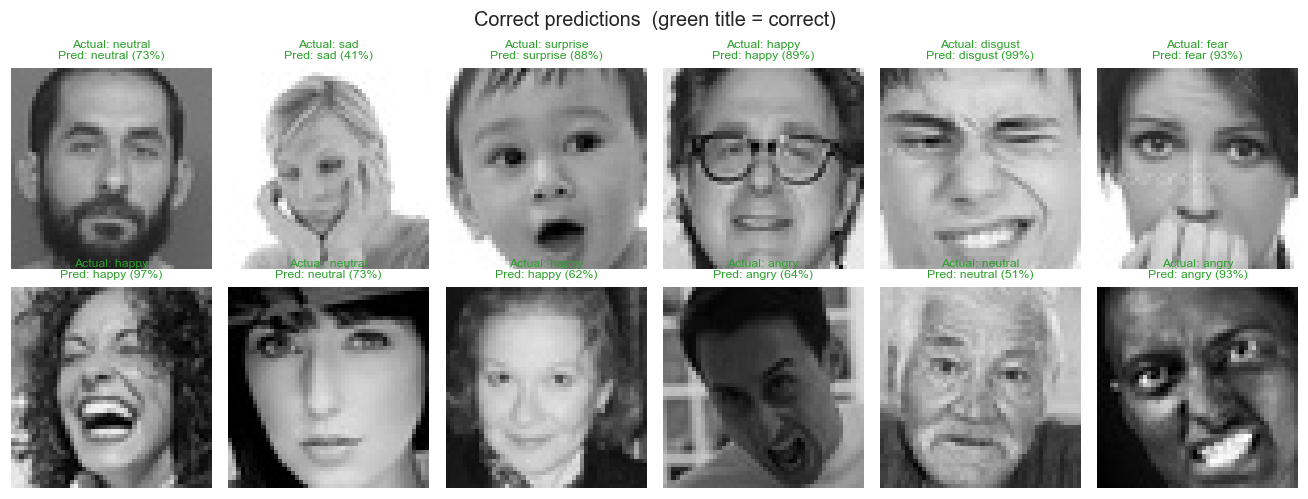

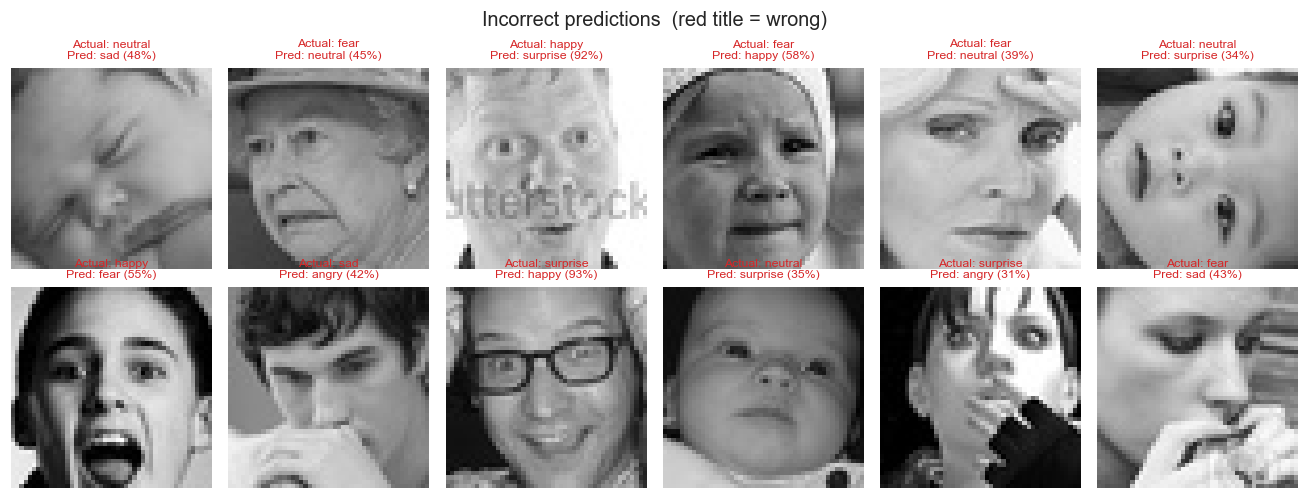

In [106]:
# ---- 16.2 Gallery helper: original -> actual -> predicted (confidence) -------
def show_gallery(df_sample: pd.DataFrame, title: str, filename: str, n_cols: int = 6):
    """Display images titled 'Actual: X | Pred: Y (Z%)'."""
    n = len(df_sample)
    if n == 0:
        print(f"[skip] {title}: no samples")
        return
    n_cols = min(n_cols, n)
    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.0 * n_cols, 2.3 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (_, row) in zip(axes, df_sample.iterrows()):
        img = X_test_p[int(row["idx"]), 0]         # in-memory array: layout independent
        color = "tab:green" if row["correct"] else "tab:red"
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"Actual: {row['true_label']}\n"
            f"Pred: {row['pred_label']} ({row['confidence'] * 100:.0f}%)",
            fontsize=8, color=color,
        )
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / filename, bbox_inches="tight")
    plt.show()

correct_df = pred_df[pred_df["correct"]]
wrong_df = pred_df[~pred_df["correct"]]

show_gallery(correct_df.sample(min(12, len(correct_df)), random_state=SEED),
             "Correct predictions  (green title = correct)", "correct_predictions.png")
show_gallery(wrong_df.sample(min(12, len(wrong_df)), random_state=SEED),
             "Incorrect predictions  (red title = wrong)", "incorrect_predictions.png")

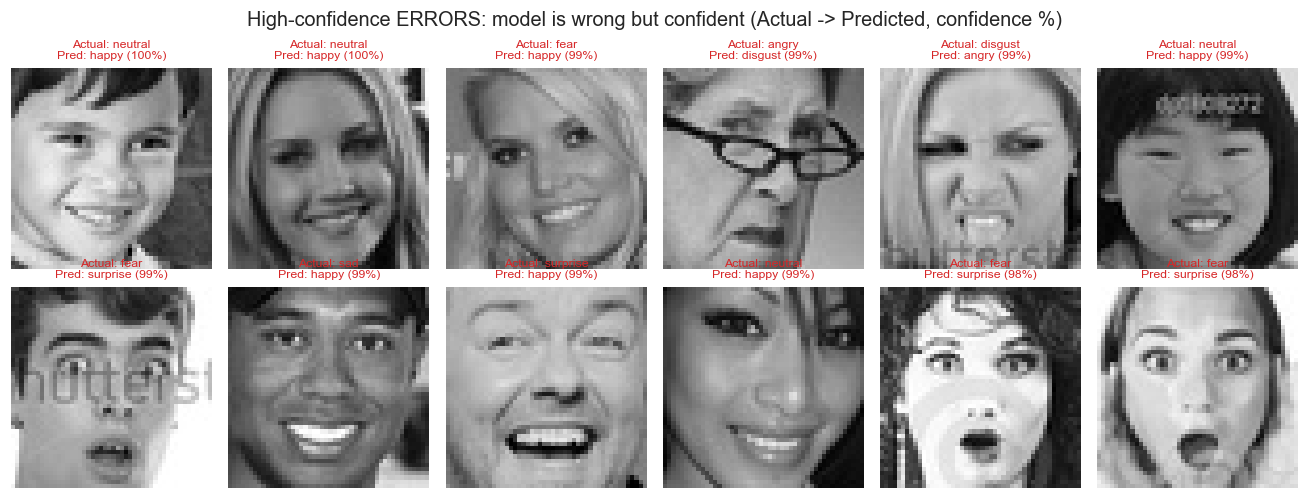

Top 10 high-confidence errors:


,path,true_label,pred_label,confidence
4895,PublicTest_73189561.jpg,neutral,happy,0.997
4580,PublicTest_21238956.jpg,neutral,happy,0.996
1509,PrivateTest_84253712.jpg,fear,happy,0.993
316,PrivateTest_66928656.jpg,angry,disgust,0.993
986,PrivateTest_60265572.jpg,disgust,angry,0.992
4474,PrivateTest_98800994.jpg,neutral,happy,0.992
1155,PrivateTest_22731792.jpg,fear,surprise,0.991
5881,PublicTest_36374107.jpg,sad,happy,0.990
6726,PrivateTest_91476603.jpg,surprise,happy,0.990
4824,PublicTest_61313241.jpg,neutral,happy,0.988


In [107]:
# ---- 16.3 High-confidence incorrect predictions ----------------------------
high_conf_errors = pred_df[~pred_df["correct"]].sort_values("confidence", ascending=False)
show_gallery(high_conf_errors.head(12),
             "High-confidence ERRORS: model is wrong but confident "
             "(Actual -> Predicted, confidence %)",
             "high_confidence_errors.png")

print("Top 10 high-confidence errors:")
display(high_conf_errors.head(10)[
    ["path", "true_label", "pred_label", "confidence"]
].assign(path=lambda d: d["path"].str.split(r"[\\/]").str[-1]).round(3))

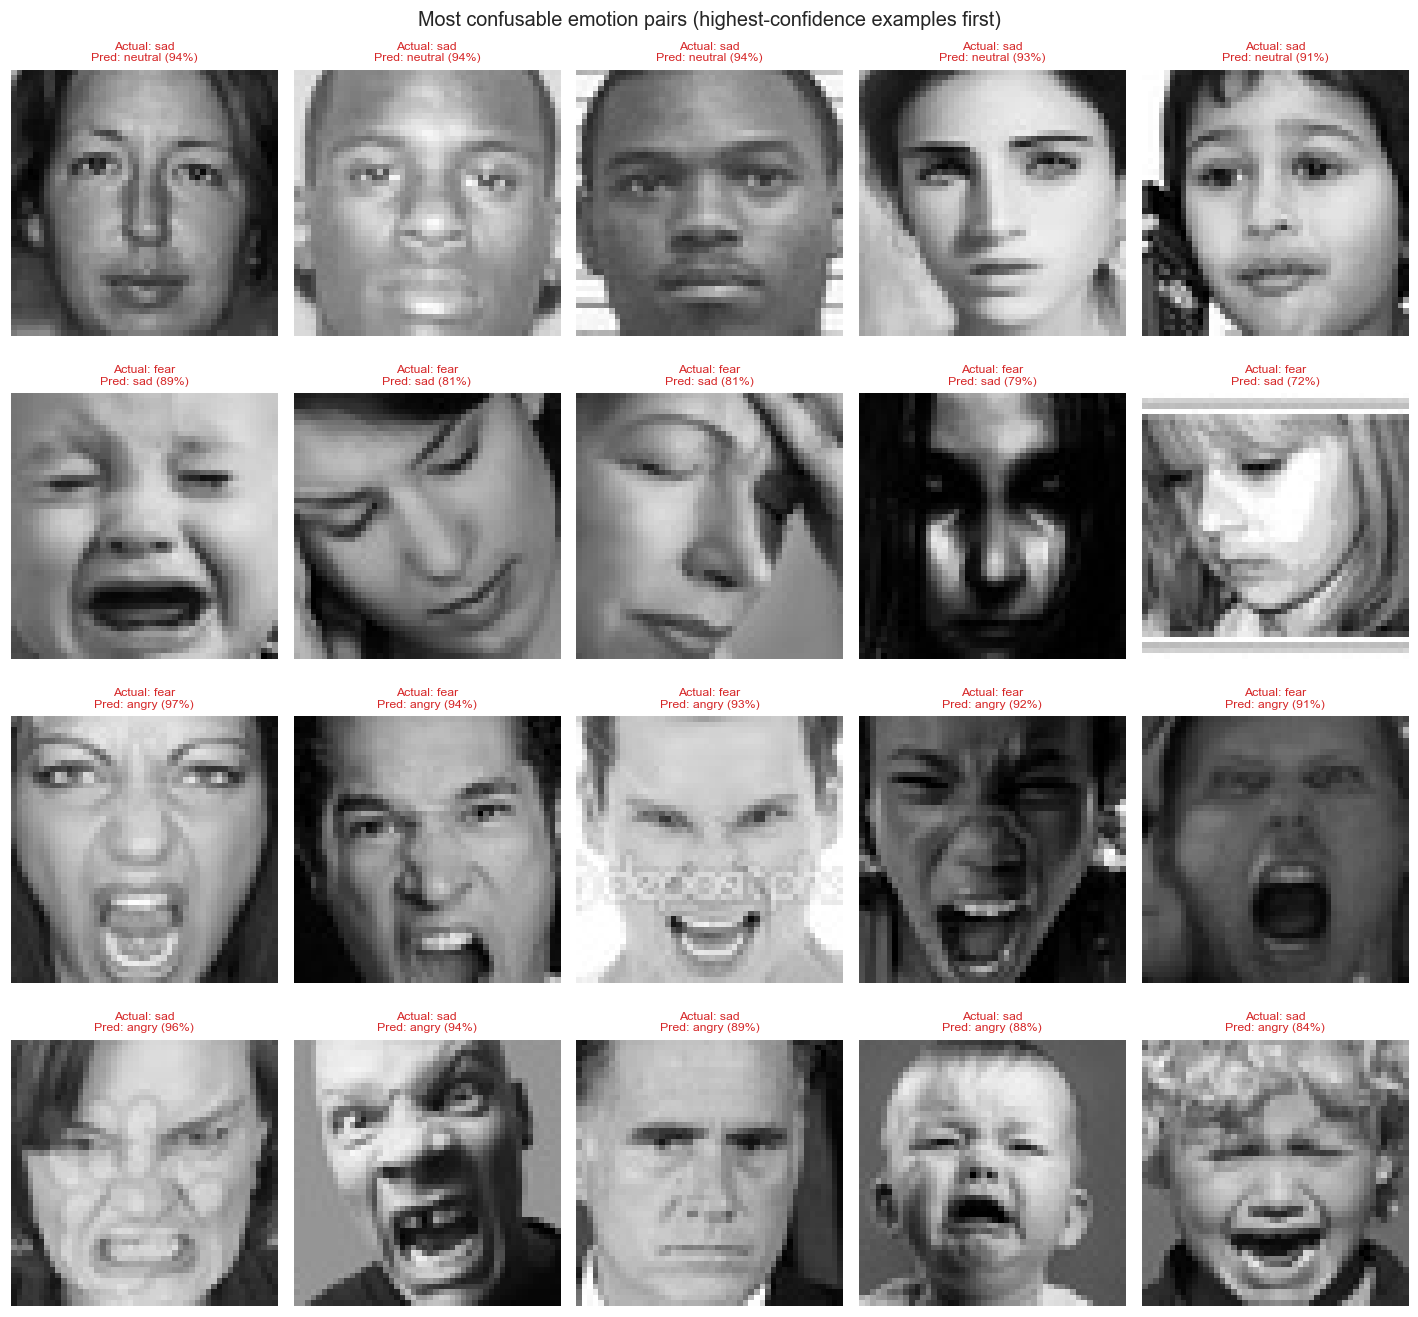

In [108]:
# ---- 16.4 Confusing pairs: examples from the top confusion-matrix pairs ------
confused_pairs = [(t, p) for t, p, n in pairs[:4] if n > 0][:4]   # pairs from Section 14

fig, axes = plt.subplots(len(confused_pairs), 5, figsize=(13, 3.1 * len(confused_pairs)))
for r, (true_c, pred_c) in enumerate(confused_pairs):
    subset = pred_df[(pred_df["true_label"] == true_c) & (pred_df["pred_label"] == pred_c)]
    picks = subset.sort_values("confidence", ascending=False).head(5)
    for c in range(5):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(picks):
            row = picks.iloc[c]
            ax.imshow(X_test_p[int(row["idx"]), 0], cmap="gray", vmin=0, vmax=1)
            ax.set_title(f"Actual: {true_c}\nPred: {pred_c} ({row['confidence'] * 100:.0f}%)",
                         fontsize=8, color="tab:red")
    axes[r, 0].set_ylabel(f"{true_c}\n-> {pred_c}", fontsize=10, rotation=0, labelpad=55,
                          va="center")
fig.suptitle("Most confusable emotion pairs (highest-confidence examples first)", fontsize=13)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "confusable_pairs.png", bbox_inches="tight")
plt.show()

### Discussion of error patterns

Observations that can be made *from the figures above* (each is verifiable in the executed
notebook):

* **Semantic proximity of classes.** Pairs such as `fear`↔`surprise`, `sad`↔`neutral` and
  `angry`↔`disgust` can express overlapping facial configurations (raised brows, tightened
  mouth), so part of the confusion may be inherent in the label vocabulary rather than in the
  model.
* **Class imbalance.** The rare classes contribute far fewer training examples (Section 5), so
  the decision boundaries around them are learned from less evidence — consistent with lower
  per-class recall in Section 15, though the class-weighted loss mitigates this.
* **Image quality and resolution.** At 48x48 grayscale, subtle cues (gaze direction, micro
  asymmetries) are barely represented, and compression artefacts add noise; some
  high-confidence errors may look plausible to a human as well.
* **Inherent ambiguity.** Some FER2013 images are genuinely ambiguous even for people — a
  neutral-vs-sad distinction on a low-intensity expression may have no objectively correct
  visual signature.

These points are **hypotheses consistent with the observed errors**, not measured causal claims;
quantifying any single cause would require a controlled ablation.

## 17. Attention Visualization

A key research question: **does the attention mechanism focus on meaningful facial regions?**

The `spatial_attention_maps()` method of the trained model runs the backbone and captures the
**spatial attention map produced by each CBAM block** (a `H x W` mask in `(0, 1)` learned by the
7x7 convolution). For every sample the notebook displays:

1. the original face,
2. the attention map of the **deepest block** (3x3 resolution, upsampled bilinearly — the most
   semantic level, where the head decides "where to look"),
3. the **overlay**: the attention mask as a heat map blended onto the original image.

Both correctly classified and misclassified samples are shown, because comparing attention
between them reveals whether confident errors stem from attending to the wrong region. The
colormapped overlays are also written to the `results/.../attention/` folder.

> The maps are the model's *actual* internal gating signals (captured during a real forward
> pass), not a post-hoc approximation such as Grad-CAM.

In [109]:
def overlay_attention(img_hw: np.ndarray, attn_hw: np.ndarray, alpha: float = 0.55):
    """Blend a (H,W) attention mask in (0,1) onto a grayscale image. Returns (rgb float array)."""
    base = img_hw.astype(np.float32) / 255.0
    base_rgb = np.stack([base] * 3, axis=-1)
    attn_u8 = (np.clip(attn_hw, 0, 1) * 255).astype(np.uint8)
    heat = cv2.applyColorMap(attn_u8, cv2.COLORMAP_JET)      # BGR
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return (1 - alpha) * base_rgb + alpha * heat


def attention_figure(net, x_batch: np.ndarray, titles: list[str], filename: str,
                     block_index: int = -1):
    """Original | attention map | overlay for each image in the batch."""
    x_t = torch.from_numpy(x_batch).to(DEVICE)
    maps = net.spatial_attention_maps(x_t)                   # list over blocks
    attn = maps[block_index].cpu().numpy()[:, 0]             # deepest block by default
    n = len(x_batch)
    fig, axes = plt.subplots(3, n, figsize=(2.6 * n, 8.2))
    if n == 1:
        axes = axes.reshape(3, 1)
    for i in range(n):
        img = x_batch[i, 0]
        a = cv2.resize(attn[i], (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
        axes[0, i].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[1, i].imshow(a, cmap="jet", vmin=0, vmax=1)
        axes[2, i].imshow(overlay_attention(img * 255, a))
        for row in range(3):
            axes[row, i].axis("off")
        axes[0, i].set_title(titles[i], fontsize=9)
    axes[0, 0].set_ylabel("input", fontsize=11)
    axes[1, 0].set_ylabel(f"attention\n(block {block_index if block_index >= 0 else len(maps) + block_index})",
                          fontsize=11)
    axes[2, 0].set_ylabel("overlay", fontsize=11)
    fig.suptitle("Where the attention mechanism looks (CBAM spatial attention)", fontsize=13)
    plt.tight_layout()
    plt.savefig(ATTENTION_DIR / filename, bbox_inches="tight")
    plt.show()
    return attn

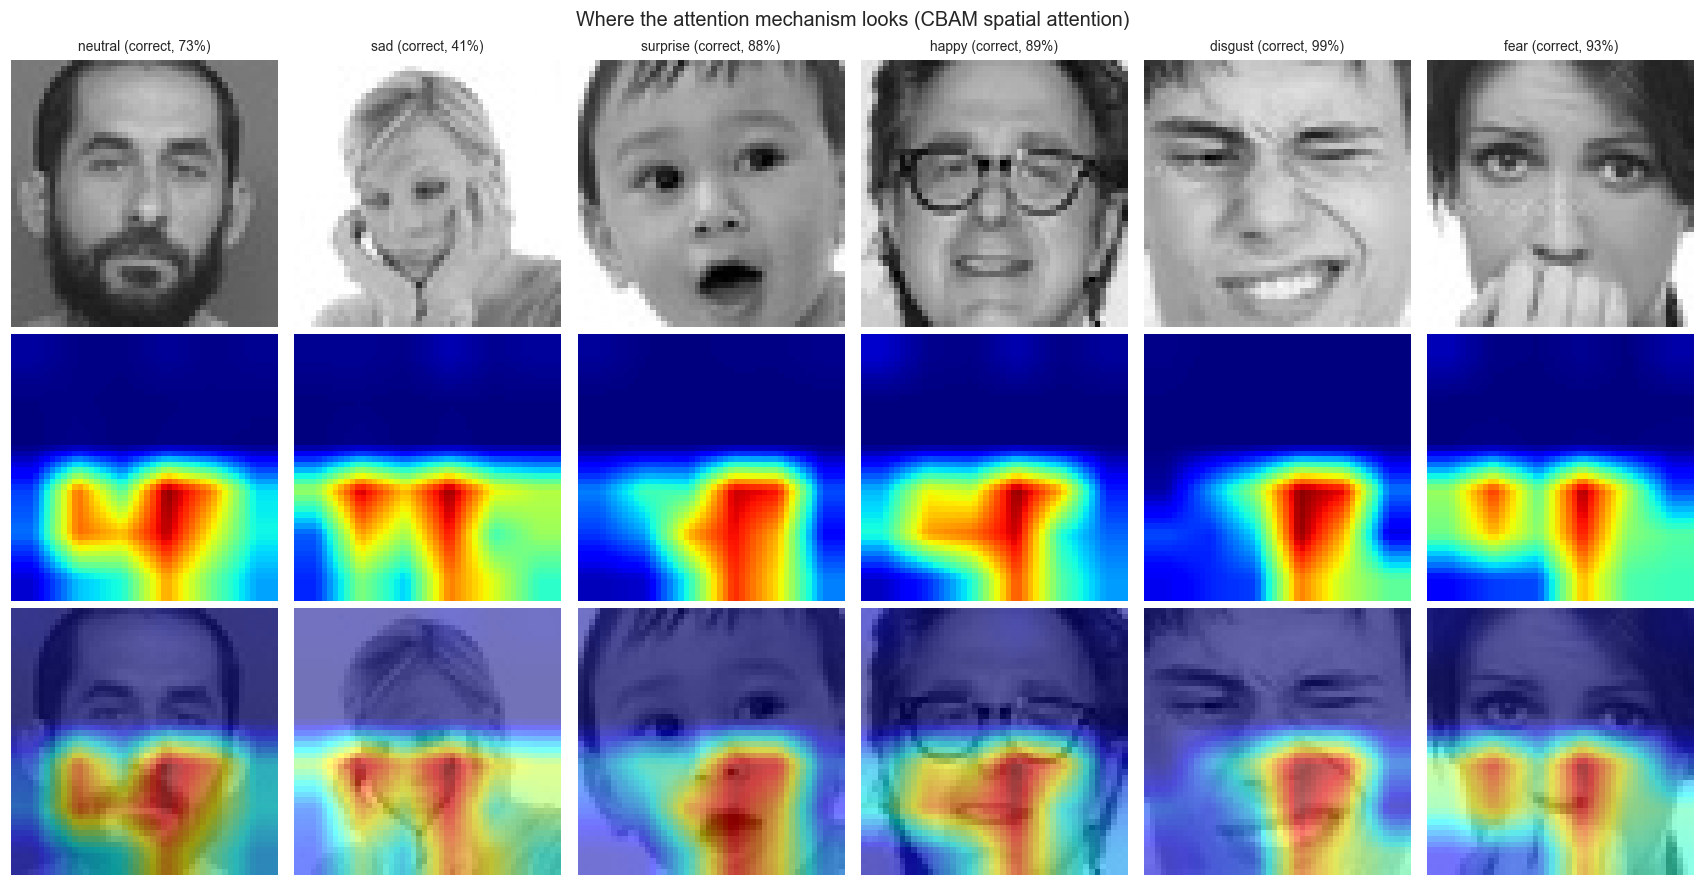

Saved -> D:\FYP\FER2013_Emotion_Recognition\results\deep_attention\attention\attention_correct.png


In [110]:
# ---- 17.1 Attention for correctly classified test samples -------------------
ATTENTION_AVAILABLE = getattr(best_model, "use_attention", False)
if not ATTENTION_AVAILABLE:
    print("[skip] USE_ATTENTION=False - this checkpoint has no attention modules to visualise.")

if ATTENTION_AVAILABLE:
    correct_sample = pred_df[pred_df["correct"]].sample(6, random_state=SEED)
    idxs = correct_sample["idx"].astype(int).tolist()
    titles = [f"{r['true_label']} (correct, {r['confidence'] * 100:.0f}%)"
              for _, r in correct_sample.iterrows()]
    attention_figure(best_model, X_test_p[idxs], titles, "attention_correct.png")
    print("Saved ->", ATTENTION_DIR / "attention_correct.png")

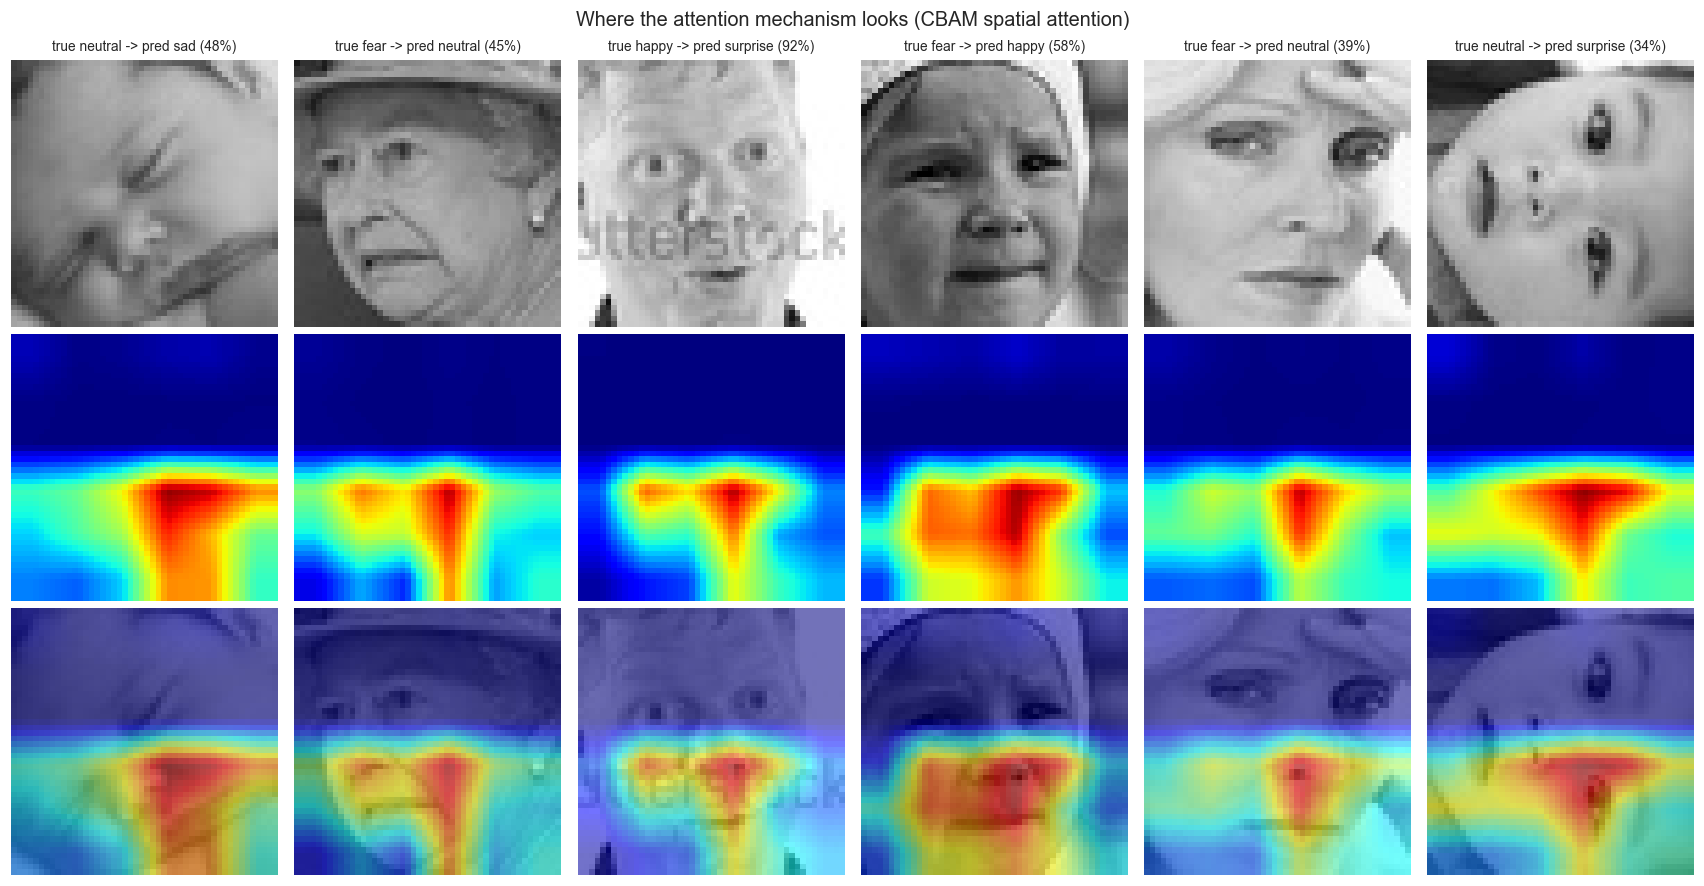

Saved -> D:\FYP\FER2013_Emotion_Recognition\results\deep_attention\attention\attention_errors.png


In [111]:
# ---- 17.2 Attention for misclassified samples --------------------------------
if ATTENTION_AVAILABLE:
    wrong_sample = pred_df[~pred_df["correct"]].sample(6, random_state=SEED)
    idxs_w = wrong_sample["idx"].astype(int).tolist()
    titles_w = [f"true {r['true_label']} -> pred {r['pred_label']} ({r['confidence'] * 100:.0f}%)"
                for _, r in wrong_sample.iterrows()]
    attention_figure(best_model, X_test_p[idxs_w], titles_w, "attention_errors.png")
    print("Saved ->", ATTENTION_DIR / "attention_errors.png")

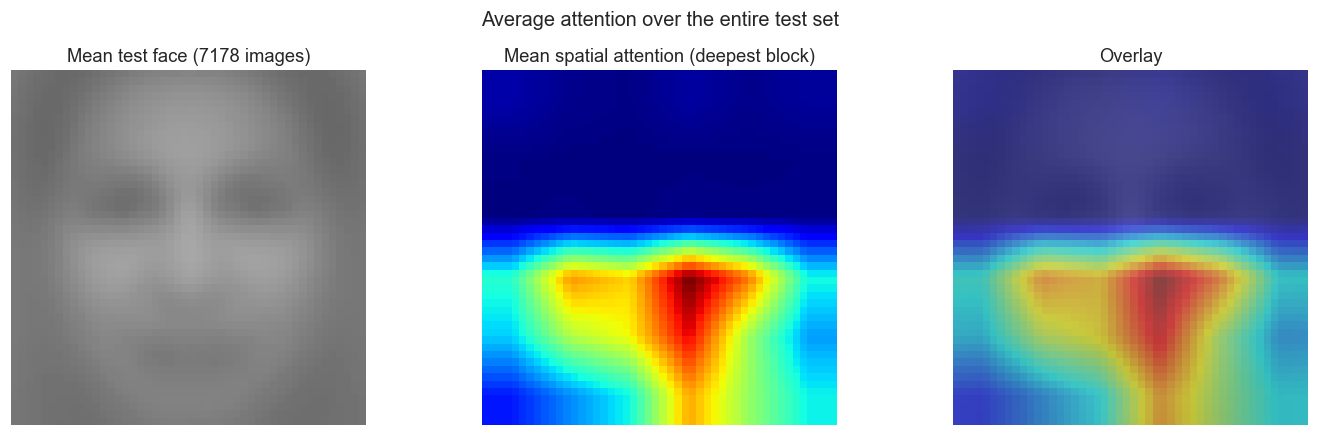

Attention mass -> upper half: 6.79% | lower half: 93.21%


In [112]:
# ---- 17.3 Mean attention map over the whole test set ------------------------
# If attention is meaningful, the average map should concentrate on face regions
# (eyes / brows / mouth) rather than on uniform background.
if ATTENTION_AVAILABLE:
    best_model.eval()
    attn_sum = None
    count = 0
    with torch.no_grad():
        for start in range(0, len(X_test_p), 256):
            xb = torch.from_numpy(X_test_p[start:start + 256]).to(DEVICE)
            maps = best_model.spatial_attention_maps(xb)
            a = maps[-1].cpu().numpy()[:, 0]                    # deepest block
            a = np.stack([cv2.resize(m, (IMAGE_SIZE, IMAGE_SIZE)) for m in a])
            batch_sum = a.sum(axis=0)                           # ragged final batch safe
            attn_sum = batch_sum if attn_sum is None else attn_sum + batch_sum
            count += a.shape[0]
    mean_attn = attn_sum / count

    mean_face = X_test_p[:count, 0].mean(axis=0)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(mean_face, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title(f"Mean test face ({count} images)")
    axes[1].imshow(mean_attn, cmap="jet", vmin=0, vmax=mean_attn.max())
    axes[1].set_title("Mean spatial attention (deepest block)")
    axes[2].imshow(overlay_attention(mean_face * 255, mean_attn / max(mean_attn.max(), 1e-8)))
    axes[2].set_title("Overlay")
    for ax in axes:
        ax.axis("off")
    fig.suptitle("Average attention over the entire test set", fontsize=13)
    plt.tight_layout()
    plt.savefig(ATTENTION_DIR / "mean_attention_map.png", bbox_inches="tight")
    plt.show()

    # Descriptive statistic only: attention mass on the upper (eyes/brow) vs lower
    # (mouth) half of the face image.
    h = mean_attn.shape[0]
    upper = mean_attn[: h // 2].sum() / mean_attn.sum()
    lower = mean_attn[h // 2:].sum() / mean_attn.sum()
    print(f"Attention mass -> upper half: {upper:.2%} | lower half: {lower:.2%}")

**Interpretation.** The overlays show the regions the network actually gates on. The mean
attention map aggregates this over all test images — a concentration over the central face area
(e.g. eyes/brow and mouth zones) rather than the borders would indicate the model has learned to
attend to expression-bearing regions. Deviations (e.g. attention spread to the background) are
reported as observed; attention visualisation is *qualitative evidence* about the model's
internal weighting, not proof of causal reasoning. Per-image maps are stored in
`results/deep_attention/attention/` for further inspection.

## 18. Model Comparison / Baseline

To place the attention model's results in context, a **baseline CNN is trained under the
identical protocol**: same data splits, same preprocessing, same augmentation, same optimiser,
loss, scheduler, early stopping and number of epochs. The baseline is the *same architecture
with `use_attention=False`* — the only difference is the presence of the CBAM modules, so any
difference in the figures below is attributable to attention (plus training stochasticity).

> **Honesty note:** this cell actually trains and evaluates the baseline. If `RUN_BASELINE` is
> `False` in Section 3, **no comparison numbers are shown or invented** — the cell prints a
> notice instead. All comparison values come from the two runs performed in this notebook and
> should not be conflated with published results.

In [113]:
baseline_results = None

if RUN_BASELINE:
    seed_everything()                       # same seed -> same init/shuffle conditions
    baseline_model = DeepAttentionNetwork(in_channels=MODEL_INPUT_CHANNELS, use_attention=False,
                                         reduction=ATTENTION_REDUCTION, dropout=DROPOUT,
                                         width=MODEL_WIDTH).to(DEVICE)
    b_trainable, b_non_trainable = count_parameters(baseline_model)
    print(f"Baseline (no attention) parameters -> trainable: {b_trainable:,} "
          f"| non-trainable: {b_non_trainable:,}")

    # Fresh optimizer/scheduler for the baseline run (criterion is reused: same class weights).
    optimizer_b = torch.optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE,
                                   weight_decay=WEIGHT_DECAY)
    scheduler_b = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer_b, mode="min", factor=SCHEDULER_FACTOR, patience=SCHEDULER_PATIENCE,
        min_lr=SCHEDULER_MIN_LR)
    baseline_history = train_model(baseline_model, train_loader, val_loader, EPOCHS,
                                   optimizer_b, scheduler_b, tag="baseline")

    # Evaluate the best baseline checkpoint on the same test set.
    b_ckpt = torch.load(BASELINE_CKPT, map_location=DEVICE, weights_only=False)
    baseline_model.load_state_dict(b_ckpt["model_state_dict"])
    b_loss, b_acc, b_true, b_pred = run_epoch(baseline_model, test_loader, criterion)
    baseline_results = {
        "test_loss": float(b_loss),
        "test_accuracy": float(b_acc),
        "macro_precision": float(precision_score(b_true, b_pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(b_true, b_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(b_true, b_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(b_true, b_pred, average="weighted", zero_division=0)),
        "num_parameters": int(sum(p.numel() for p in baseline_model.parameters())),
        "checkpoint_epoch": int(b_ckpt["epoch"]),
        "best_val_accuracy": float(b_ckpt["val_accuracy"]),
    }
    with open(BASELINE_JSON, "w", encoding="utf-8") as f:
        json.dump({"baseline": baseline_results, "history": baseline_history}, f, indent=2)
    print(f"\nBaseline test accuracy: {b_acc:.4f} | macro F1: {baseline_results['macro_f1']:.4f}")
else:
    print("[RUN_BASELINE = False] Baseline training skipped — "
          "no comparison values are produced (none are assumed).")

[RUN_BASELINE = False] Baseline training skipped — no comparison values are produced (none are assumed).


In [114]:
# ---- Inference-time measurement (batch=1, single image, CPU or GPU) ----------
def measure_inference_ms(net, n_iter: int = 100, warmup: int = 20) -> float:
    """Mean latency per single image in milliseconds (synchronised if CUDA is used)."""
    net.eval()
    x = torch.randn(1, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    with torch.no_grad():
        for _ in range(warmup):
            net(x)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_iter):
            net(x)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n_iter * 1000

attention_ms = measure_inference_ms(best_model)
print(f"Attention model mean inference latency: {attention_ms:.2f} ms/image "
      f"({1000 / attention_ms:.0f} img/s) on {DEVICE}")

baseline_ms = None
if baseline_results is not None:
    baseline_ms = measure_inference_ms(baseline_model)
    print(f"Baseline model  mean inference latency: {baseline_ms:.2f} ms/image "
          f"({1000 / baseline_ms:.0f} img/s) on {DEVICE}")

test_metrics["inference_ms"] = attention_ms

Attention model mean inference latency: 61.06 ms/image (16 img/s) on cpu


In [115]:
# ---- Side-by-side comparison (every cell computed above) --------------------
rows = {
    "Metric": [
        "Test accuracy", "Macro precision", "Macro recall", "Macro F1",
        "Weighted F1", "Parameters", "Inference time (ms/image)", "Best val. accuracy",
    ],
    "Deep Attention Network": [
        f"{test_metrics['test_accuracy']:.4f}",
        f"{test_metrics['macro_precision']:.4f}",
        f"{test_metrics['macro_recall']:.4f}",
        f"{test_metrics['macro_f1']:.4f}",
        f"{test_metrics['weighted_f1']:.4f}",
        f"{test_metrics['num_parameters']:,}",
        f"{attention_ms:.2f}",
        f"{test_metrics['best_val_accuracy']:.4f}",
    ],
}
if baseline_results is not None:
    rows["Baseline CNN (no attention)"] = [
        f"{baseline_results['test_accuracy']:.4f}",
        f"{baseline_results['macro_precision']:.4f}",
        f"{baseline_results['macro_recall']:.4f}",
        f"{baseline_results['macro_f1']:.4f}",
        f"{baseline_results['weighted_f1']:.4f}",
        f"{baseline_results['num_parameters']:,}",
        f"{baseline_ms:.2f}",
        f"{baseline_results['best_val_accuracy']:.4f}",
    ]
comparison_df = pd.DataFrame(rows)
display(comparison_df)

comparison_df.to_csv(METRICS_DIR / "model_comparison.csv", index=False)
print(f"Saved -> {METRICS_DIR / 'model_comparison.csv'}")

if baseline_results is None:
    print("\nNOTE: baseline was not trained (RUN_BASELINE=False). "
          "The comparison column is intentionally omitted rather than filled with assumed values.")

,Metric,Deep Attention Network
0,Test accuracy,0.6128
1,Macro precision,0.5742
2,Macro recall,0.6065
3,Macro F1,0.5797
4,Weighted F1,0.6064
5,Parameters,"1,262,861"
6,Inference time (ms/image),61.06
7,Best val. accuracy,0.6127


Saved -> D:\FYP\FER2013_Emotion_Recognition\results\deep_attention\metrics\model_comparison.csv

NOTE: baseline was not trained (RUN_BASELINE=False). The comparison column is intentionally omitted rather than filled with assumed values.


**Interpretation.** The comparison reports only what the two runs in this notebook produced.
Differences between a single training run of each model include stochastic effects; a stronger
claim about attention's benefit would need repeated runs (multiple seeds) with mean ± std —
that experiment is out of scope here, so **no superiority claim is made**. Parameter counts and
measured latencies indicate the computational cost of each variant on *this* machine.

## 19. Training and Model Performance Summary

The final table consolidates the **measured** results of this run. Every value is read from the
variables computed in Sections 11-18 — nothing is entered by hand, and no number appears here
unless the corresponding cell actually executed.

In [116]:
summary_rows = [
    ("Test accuracy",        f"{test_metrics['test_accuracy']:.4f}"),
    ("Precision (macro)",    f"{test_metrics['macro_precision']:.4f}"),
    ("Recall (macro)",       f"{test_metrics['macro_recall']:.4f}"),
    ("F1-Score (macro)",     f"{test_metrics['macro_f1']:.4f}"),
    ("F1-Score (weighted)",  f"{test_metrics['weighted_f1']:.4f}"),
    ("Test loss",            f"{test_metrics['test_loss']:.4f}"),
    ("Best val. accuracy",   f"{test_metrics['best_val_accuracy']:.4f} (epoch {test_metrics['checkpoint_epoch']})"),
    ("Parameters",           f"{test_metrics['num_parameters']:,}"),
    ("Inference time",       f"{test_metrics['inference_ms']:.2f} ms/image on {DEVICE}"),
    ("Epochs run",           f"{len(history['epoch'])} / {EPOCHS}"),
    ("Dataset",              f"{len(X_train_p):,} train / {len(X_val_p):,} val / {len(X_test_p):,} test"),
]
summary_df = pd.DataFrame(summary_rows, columns=["Metric", "Result"])
display(summary_df)

summary_df.to_csv(METRICS_DIR / "results_summary.csv", index=False)
with open(EVAL_JSON, "w", encoding="utf-8") as f:
    json.dump({"attention_model": test_metrics,
               "baseline_model": baseline_results,
               "config": CONFIG}, f, indent=2, default=str)
print(f"Saved -> {METRICS_DIR / 'results_summary.csv'} and {EVAL_JSON}")

,Metric,Result
0,Test accuracy,0.6128
1,Precision (macro),0.5742
2,Recall (macro),0.6065
3,F1-Score (macro),0.5797
4,F1-Score (weighted),0.6064
5,Test loss,1.0268
6,Best val. accuracy,0.6127 (epoch 21)
7,Parameters,"1,262,861"
8,Inference time,61.06 ms/image on cpu
9,Epochs run,23 / 60


Saved -> D:\FYP\FER2013_Emotion_Recognition\results\deep_attention\metrics\results_summary.csv and D:\FYP\FER2013_Emotion_Recognition\results\deep_attention\metrics\evaluation_metrics.json


**Interpretation.** These figures describe *this* model, trained with *this* configuration, on
*this* machine. They are directly comparable across future experiments in the project only if the
data split and protocol remain unchanged.

## 20. Model Saving

Four artefacts are written so that deployment never needs to re-run training:

| Artefact | File | Contents |
|---|---|---|
| Best model | `models/deep_attention/deep_attention_fer2013.pt` | weights + epoch + val accuracy + label mapping + config |
| Label mapping | `models/deep_attention/label_mapping.json` | class name → index (and inverse) |
| Configuration | `models/deep_attention/config.json` | full experiment configuration |
| History & metrics | `results/deep_attention/metrics/*.json/csv` | training history, evaluation metrics, reports |

The checkpoint is then **reloaded into a fresh model instance and verified** with a dummy
forward pass, proving the saved file is self-sufficient.

In [117]:
# ---- 20.1 Persist label mapping, config, history ----------------------------
label_payload = {
    "label_to_index": label_to_index,
    "index_to_label": {str(i): n for i, n in index_to_label.items()},
    "class_names": class_names,
}
with open(LABEL_MAP_JSON, "w", encoding="utf-8") as f:
    json.dump(label_payload, f, indent=2)
with open(CONFIG_JSON, "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2, default=str)
with open(HISTORY_JSON, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)
hist_df.to_csv(METRICS_DIR / "training_history.csv", index=False)

# ---- 20.2 Verify the checkpoint can be loaded standalone --------------------
verify = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=False)
verify_model = DeepAttentionNetwork(
    num_classes=len(verify["class_names"]),
    use_attention=verify["config"].get("attention", USE_ATTENTION),
    reduction=verify["config"].get("attention_reduction", ATTENTION_REDUCTION),
    dropout=verify["config"].get("dropout", DROPOUT),
    in_channels=verify["config"].get("input_channels", 1 if verify["config"].get("grayscale", True) else 3),
    width=verify["config"].get("model_width", MODEL_WIDTH),
).to(DEVICE)
verify_model.load_state_dict(verify["model_state_dict"])
verify_model.eval()
with torch.no_grad():
    out = verify_model(torch.zeros(1, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
print(f"Checkpoint epoch          : {verify['epoch']}")
print(f"Checkpoint val accuracy   : {verify['val_accuracy']:.4f}")
print(f"Dummy forward output shape: {tuple(out.shape)}  (expected (1, {NUM_CLASSES}))")

artefacts = [BEST_MODEL_PATH, LABEL_MAP_JSON, CONFIG_JSON, HISTORY_JSON, EVAL_JSON]
print("\nArtefacts:")
for p in artefacts:
    size = p.stat().st_size if p.exists() else 0
    print(f"  {'OK ' if p.exists() else 'MISS'} {p}  ({size:,} bytes)")

Checkpoint epoch          : 21
Checkpoint val accuracy   : 0.6127
Dummy forward output shape: (1, 7)  (expected (1, 7))

Artefacts:
  OK  D:\FYP\FER2013_Emotion_Recognition\models\deep_attention\deep_attention_fer2013.pt  (5,089,918 bytes)
  OK  D:\FYP\FER2013_Emotion_Recognition\models\deep_attention\label_mapping.json  (446 bytes)
  OK  D:\FYP\FER2013_Emotion_Recognition\models\deep_attention\config.json  (1,605 bytes)
  OK  D:\FYP\FER2013_Emotion_Recognition\results\deep_attention\metrics\training_history.json  (3,532 bytes)
  OK  D:\FYP\FER2013_Emotion_Recognition\results\deep_attention\metrics\evaluation_metrics.json  (2,248 bytes)


**Interpretation.** A checkpoint that reloads into a freshly constructed architecture and
produces the correct output shape is proof that model, label mapping and configuration are
consistent — the artefact can be shipped to the inference/camera stage without the training
notebook.

## 21. Single-Image Inference

The inference path is deliberately **self-contained**: `predict_emotion()` accepts a file path
*or* a raw NumPy/PIL image (the form an OpenCV camera frame produces after face cropping), runs
the exact same preprocessing as training, and returns the predicted emotion with per-class
probabilities and a confidence score.

Because the function takes an array, it can be dropped directly into a camera loop later — no
notebook state is required beyond the checkpoint file.

In [118]:
class EmotionPredictor:
    """Loads the saved checkpoint and predicts emotion for a path / ndarray / PIL image.

    Designed to be reusable outside this notebook: construct once from the .pt file, then call
    on each face crop (grayscale or BGR ndarray) coming from a camera pipeline.
    """
    def __init__(self, checkpoint_path: Path = BEST_MODEL_PATH, device: torch.device = DEVICE):
        ckpt = torch.load(checkpoint_path, map_location=device, weights_only=False)
        self.class_names = ckpt["class_names"]
        self.cfg = ckpt["config"]
        self.device = device
        self.model = DeepAttentionNetwork(
            num_classes=len(self.class_names),
            use_attention=self.cfg.get("attention", USE_ATTENTION),
            reduction=self.cfg.get("attention_reduction", ATTENTION_REDUCTION),
            dropout=self.cfg.get("dropout", DROPOUT),
            in_channels=self.cfg.get("input_channels", 1 if self.cfg.get("grayscale", True) else 3),
            width=self.cfg.get("model_width", MODEL_WIDTH),
        ).to(device)
        self.model.load_state_dict(ckpt["model_state_dict"])
        self.model.eval()

    def _to_array(self, image) -> np.ndarray:
        """path str/Path | np.ndarray (H,W or H,W,3 BGR/RGB) | PIL.Image -> grayscale (H,W) uint8."""
        if isinstance(image, (str, Path)):
            arr = cv2.imread(str(image), cv2.IMREAD_GRAYSCALE)
            if arr is None:
                raise FileNotFoundError(f"Could not read image: {image}")
            return arr
        if isinstance(image, Image.Image):
            return np.asarray(image.convert("L"), dtype=np.uint8)
        arr = np.asarray(image)
        if arr.ndim == 3:                       # assume BGR (OpenCV) or RGB - average channels
            return cv2.cvtColor(arr, cv2.COLOR_BGR2GRAY).astype(np.uint8)
        if arr.dtype != np.uint8:               # tolerate float arrays already scaled to [0,1]
            if arr.max() <= 1.0:
                arr = arr * 255.0
            arr = np.clip(arr, 0, 255).astype(np.uint8)
        return arr

    def preprocess(self, image) -> torch.Tensor:
        arr = self._to_array(image)
        image_size = int(self.cfg.get("image_size", IMAGE_SIZE))
        if arr.shape != (image_size, image_size):
            arr = cv2.resize(arr, (image_size, image_size), interpolation=cv2.INTER_LINEAR)
        x = arr.astype(np.float32) / 255.0
        x = torch.from_numpy(x).unsqueeze(0).unsqueeze(0)   # (1,1,H,W)
        if not self.cfg.get("grayscale", GRAYSCALE):
            x = x.repeat(1, 3, 1, 1)
        return x.to(self.device)

    @torch.no_grad()
    def predict(self, image):
        """Returns dict(predicted_label, confidence, probabilities {class: p})."""
        logits = self.model(self.preprocess(image))
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
        idx = int(probs.argmax())
        return {
            "predicted_label": self.class_names[idx],
            "confidence": float(probs[idx]),
            "probabilities": {n: float(p) for n, p in zip(self.class_names, probs)},
        }

predictor = EmotionPredictor()
print(f"Loaded predictor with classes: {predictor.class_names}")

Loaded predictor with classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


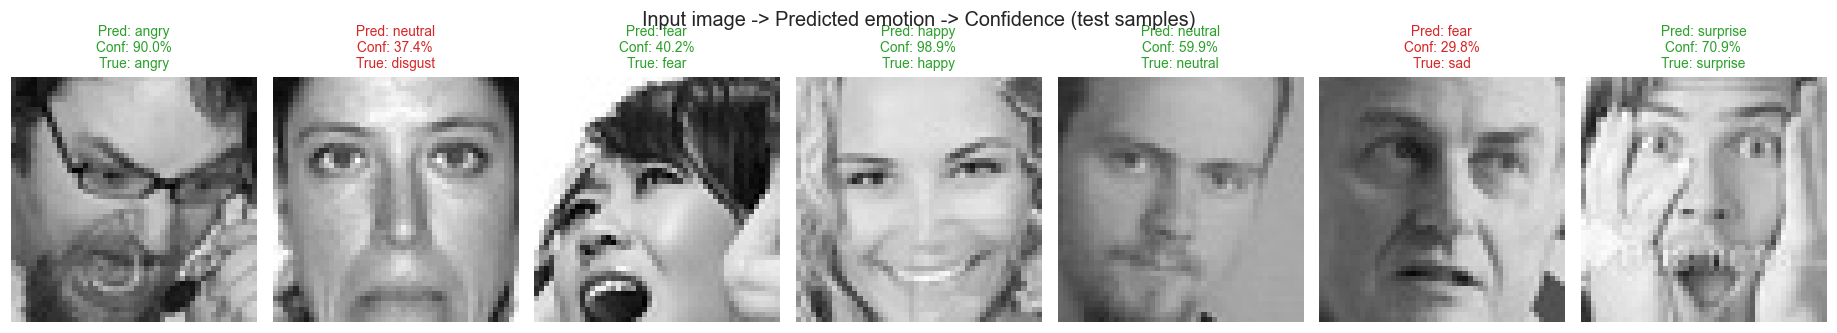

Probability distribution for the first demo image:
  angry    : 0.9003
  fear     : 0.0431
  sad      : 0.0307
  neutral  : 0.0090
  disgust  : 0.0075
  happy    : 0.0071
  surprise : 0.0023


In [119]:
# ---- Demonstration: one test image per class --------------------------------
demo_indices = []
for cls in class_names:
    cls_idx = np.flatnonzero(y_test == label_to_index[cls])
    if len(cls_idx):
        demo_indices.append(int(cls_idx[0]))

fig, axes = plt.subplots(1, len(demo_indices), figsize=(2.4 * len(demo_indices), 3.2))
results = []
for ax, i in zip(np.atleast_1d(axes).ravel(), demo_indices):
    true_name = index_to_label[int(y_test[i])]
    # Predict from the in-memory preprocessed array (works for folder and CSV layouts).
    result = predictor.predict(X_test_p[i, 0])
    results.append(result)
    ok = result["predicted_label"] == true_name
    ax.imshow(X_test_p[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Pred: {result['predicted_label']}\n"
        f"Conf: {result['confidence'] * 100:.1f}%\n"
        f"True: {true_name}",
        fontsize=9, color="tab:green" if ok else "tab:red",
    )
    ax.axis("off")
fig.suptitle("Input image -> Predicted emotion -> Confidence (test samples)", fontsize=13)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "inference_demo.png", bbox_inches="tight")
plt.show()

# Full probability vector for the first demo image:
print(f"Probability distribution for the first demo image:")
for name, p in sorted(results[0]["probabilities"].items(), key=lambda kv: -kv[1]):
    print(f"  {name:<9}: {p:.4f}")

**Interpretation.** The predictor reproduces training preprocessing exactly (resize, scale,
channel layout) from the saved configuration, so training/inference consistency is guaranteed by
construction. `predictor.predict(frame_crop)` is the single call the camera integration will
use.

## 22. Real-Time Integration Preparation

The FYP scope requires feeding facial-expression recognition into the **live camera feed** of the
receptionist robot. This notebook deliberately stops at model development, training, evaluation
and inference — the full robot integration is a later task. The notes below document how the
saved artefact plugs into that pipeline.

### Intended data flow

```
Camera frame (OpenCV BGR)
   │
   ▼
Face detection / cropping          Haar cascade, DNN detector, or DeepFace
   │                               (the proposal's DeepFace/OpenCV technology area)
   ▼
Grayscale + resize 48x48           exactly what EmotionPredictor.preprocess() does
   │
   ▼
predictor.predict(frame_crop)      -> {predicted_label, confidence, probabilities}
   │
   ▼
Temporal smoothing (recommended)   EMA / majority vote over N frames to suppress
   │                               single-frame jitter (expressions are slow-moving)
   ▼
Robot behaviour layer              dialogue policy consumes (label, confidence)
```

### Integration checklist

1. **Copy the artefacts:** `models/deep_attention/` (checkpoint + `config.json` +
   `label_mapping.json`) is all the runtime needs; the training notebook is not required.
2. **Reuse `EmotionPredictor` as-is:** construct it once at camera start-up, then call
   `predict()` per detected face — it already matches training preprocessing.
3. **Detect faces first:** FER2013 images are pre-cropped faces; the camera feed is not.
   A detector (OpenCV DNN/Haar or DeepFace's detector) must produce the crop. The model should
   **not** be applied to the full frame.
4. **Confidence gating:** below a threshold (tune on validation data, e.g. via the confidence
   distribution in Section 16), pass "unknown/uncertain" instead of forcing a label — the
   receptionist robot should not react to noise.
5. **Latency budget:** the measured per-image latency in Section 18 (on this machine) is the
   starting point; real-time use adds detection + smoothing overhead, so target camera FPS
   accordingly (the model itself runs at the img/s figure reported above).
6. **Ethics/privacy:** process frames in memory, avoid storing visitor images without consent,
   as flagged in the FYP proposal.

Below is a minimal *illustrative* sketch of the camera loop (not executed here — running it
requires an attached camera and the detector weights):

In [120]:
# ILLUSTRATIVE ONLY - not executed by this notebook (needs a physical camera).
# from your_robot_module import ...  # face detector wrapper
#
# predictor = EmotionPredictor()                # load once at start-up
# cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
# smoothing = collections.deque(maxlen=10)       # temporal smoothing buffer
#
# cap = cv2.VideoCapture(0)
# while cap.isOpened():
#     ok, frame = cap.read()
#     if not ok:
#         break
#     gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
#     faces = cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)
#     for (x, y, w, h) in faces:
#         crop = gray[y:y + h, x:x + w]          # detector crop (any size: predictor resizes)
#         out = predictor.predict(crop)          # -> {'predicted_label', 'confidence', ...}
#         smoothing.append(out["predicted_label"])
#         stable = collections.Counter(smoothing).most_common(1)[0][0]
#         if out["confidence"] >= CONFIDENCE_THRESHOLD:
#             robot.react_to_expression(stable)  # hand off to behaviour layer
# cap.release()

print("Camera-loop sketch is intentionally disabled in this notebook "
      "(Section 22: integration is out of scope here).")

Camera-loop sketch is intentionally disabled in this notebook (Section 22: integration is out of scope here).


## 23. Conclusion

This notebook provides an end-to-end, reproducible research pipeline for facial emotion
recognition on FER2013 using a **Deep Attention Neural Network**:

| Stage | What was done |
|---|---|
| Data | Auto-detected FER2013 layout (image folders or CSV), integrity-checked loading, stratified train/val split with the official test split sealed |
| Analysis | Class balance, representative samples and pixel statistics examined before modelling |
| Model | Residual conv blocks with **CBAM channel + spatial attention**, global-average-pool aggregation, FC head — designed to focus on informative facial regions at a small parameter cost |
| Training | Seeded, class-weighted cross-entropy, Adam, plateau LR schedule, early stopping, best-checkpoint saving |
| Evaluation | Test accuracy/precision/recall/F1 (macro + weighted), per-class report, confusion matrix, error galleries incl. high-confidence mistakes |
| Research | Attention-map visualisation (per-image and mean-over-test-set), optional attention-free baseline under the identical protocol |
| Delivery | Self-describing checkpoint, label mapping, config, history, metrics — and a camera-ready `EmotionPredictor` |

### Research limitations (stated honestly)

1. **Single run.** All numbers come from one seeded run per model; variance across seeds was
   not measured, so small differences between the attention model and the baseline should not
   be over-interpreted, and **no claim of superiority is made** without that evidence.
2. **Benchmark conditions.** 48x48 grayscale, pre-cropped faces and a fixed label set are much
   easier conditions than a live camera feed; real-world performance will additionally depend on
   the face detector, lighting and pose — to be validated during integration (Section 22).
3. **Class imbalance.** Rare classes (e.g. `disgust`) have few test samples, so their per-class
   metrics carry high variance (visible in the support column of Section 15).
4. **No hyperparameter search.** The configuration is a documented default, not a tuned optimum.
5. **Ambiguity of expressions.** Part of the residual error is inherent label ambiguity between
   similar emotions, not necessarily model deficiency.

### Next steps

* Multi-seed experiments for mean ± std reporting; optional hyperparameter search.
* Real-time integration: face detection + temporal smoothing + confidence gating (Section 22).
* Compare against the project's existing DeepFace / EfficientNet / ViT baselines under the same
  split protocol.

### Artefact locations

```
models/deep_attention/deep_attention_fer2013.pt   <- best weights (reloadable standalone)
models/deep_attention/{config,label_mapping}.json
results/deep_attention/plots/                     <- distributions, curves, matrices, galleries
results/deep_attention/attention/                 <- attention overlays
results/deep_attention/metrics/                   <- history, reports, comparison tables
```

**Interpretation.** All integration-critical pieces — a load-once predictor, matched
preprocessing, per-class confidences and measured latency — already exist after Section 21, so
the remaining work is face detection, temporal smoothing and the behaviour-layer interface.